# MoA Prediction — Multi-Model Ensemble

Kaggle competition: [Mechanisms of Action (MoA) Prediction](https://www.kaggle.com/competitions/lish-moa)

Multi-label classification of 206 biological mechanisms of action from
gene-expression and cell-viability profiles.

## Workflow

This notebook is organised into the following numbered steps. Section headers and
in-code comments are tagged with the matching step number (`# Step N` or
`# Step N.k`), so any block of code can be traced back to its place in the pipeline.

1. **Setup:** imports and global configuration (including the CV protocol, `CV_SCHEME`, and the
   model hyperparameters, read from `best_hyperparameters.json`, Step 1.5)
2. **Data loading, cleaning and exploration; drug identifiers and CV splitting**
   (`train_drug.csv`: outer folds and inner split grouped by `drug_id`)
3. **Feature engineering:** row statistics, categorical encoding
4. **Model architectures:** TabularResNet, FT-Transformer
5. **Evaluation metric:** mean multi-label binary log loss
6. **Loss variants:** label smoothing
7. **Per-fold training routine:** single model, single fold, single seed, with an
   inner validation split (grouped by drug when `CV_SCHEME = "grouped"`) used only for model selection
8. **Per-fold preprocessing pipelines:** RankGauss(+ PCA) and RankGauss-only variants
9. **Cross-validation — neural network ensemble:** (ResNet, FT-Transformer),
   multi-seed bagging, 30 jobs scheduled on a pool of parallel workers across GPUs
10. **Third model — CatBoost:** on raw (non-PCA) features
11. **Ensemble blending:** nested-CV weight search over the three base models
12. **Experiment logging**
13. **Submission building and sanity checks**
14. **Main pipeline:** runs steps 2–13 end to end and writes `submission.csv`
    - 14.0 clean cached pipelines
    - 14.1 load, clean and explore data; attach drug ids
    - 14.2 feature engineering
    - 14.2b CV splits
    - 14.3 neural-network cross-validation
    - 14.4 CatBoost cross-validation
    - 14.5 ensemble blending
    - 14.6 experiment logging
    - 14.7 test-set preprocessing and inference
    - 14.8 submission and sanity checks
    - 14.9 export metadata for inference notebook
15. **Final checks and analyses:**
    - 15.1 differences between AMP and fp32
    - 15.2 trivial baseline
    - 15.3 OOF predictions saving
    - 15.4 per-target error analysis (difficult MoAs, behaviour on rare targets)
    - 15.5 CV-protocol diagnostics (seen vs unseen drugs, gap to the Kaggle score, comparison with the row-wise run)

## Cross-validation protocol

The competition hosts published `train_drug.csv`, which maps every `sig_id` to its `drug_id`.
`CV_SCHEME` (Step 1.3) selects the protocol:

* `"grouped"`: all rows of a compound stay in the same fold. The outer folds are
  multilabel-stratified **at drug level** (a drug counts as positive for a target if any of
  its rows is), and the inner split used for model selection is grouped in the same way.
* `"hybrid"` (default): like `"grouped"`, except that the rows of the drugs with more than
  `HYBRID_MIN_ROWS` rows are split row by row (multilabel-stratified). Very frequently measured
  compounds can be much larger than a fold's share and make pure grouping unbalanced and
  pessimistic for the targets they dominate. The inner split follows the same rule.
* `"row"`: the earlier protocol (every row is an independent unit). It can place the same
  compound in the training and validation part of a fold. It is kept to reproduce the earlier
  results and for the comparison in Step 15.5.

## Known limitations

* In `"hybrid"` mode the threshold `HYBRID_MIN_ROWS` is a design choice, not a measured
  quantity. Whether frequent compounds also appear in the hidden test set cannot be checked
  (the test set has no drug identifier), so neither the hybrid nor the pure grouped CV can be
  declared the faithful one; their difference brackets the uncertainty.
* Grouping is done at drug level, so fold sizes (in rows) and per-target positives are only
  approximately balanced, because drugs have very different numbers of rows. Step 14.2b prints the
  actual fold sizes. Pure grouping also assumes that the compounds of the hidden test set are
  disjoint from the training ones; the test set has no drug identifier, so this cannot be
  checked from the data provided. If the test set shares compounds with the training set,
  the grouped CV is pessimistic rather than faithful.
* The grouped CV is a diagnostic of the earlier gap between CV and Kaggle score, not a proof:
  Step 15.5 prints how much of that gap it reproduces, and other causes (composition shift of
  the test set, approximate rescaling by the treated share) are not excluded.
* Early stopping, learning-rate scheduling and best-epoch selection of the neural
  networks use an **inner** validation split carved out of each training fold. The
  outer fold that produces the out-of-fold (OOF) predictions is never used for
  model selection. CatBoost uses a fixed number of iterations.
* The hyperparameters of the three models come from `best_hyperparameters.json`, written by the
  separate tuning notebook (Step 1.5; `USE_TUNED_HYPERPARAMETERS = False` restores the previous
  defaults). They were selected on validation folds, so the CV scores of this notebook are optimistic
  by an unknown amount, at least on the folds used for tuning. The architecture of the networks and
  the number of CatBoost iterations were chosen earlier, by looking at the row-wise OOF scores, and
  only the parameters present in the file are replaced.
  The tuned values were selected on compound-aware (`hybrid`) folds that overlap the validation
  folds of this run, so they may favour the `hybrid` protocol more than the `row` and `grouped` ones.
* The FT-Transformer is a simplified variant inspired by Gorishniy et al. (2021):
  post-LayerNorm encoder, GELU feed-forward, no ReGLU.

**Note:** this notebook is saved with the outputs of run G3 (`CV_SCHEME = "grouped"`, tuned hyperparameters from `best_hyperparameters_hybrid.json`, the output of `moa-tuning-hybrid.ipynb`, 2× NVIDIA T4, 89.9 min). It has the same code and the same hyperparameters as `moa-training.ipynb` (run H2, `hybrid`) and the other copy in `software/cv-scheme-runs/`; only `CV_SCHEME` differs, so the nested-CV scores of R3, H2 and G3 are comparable with one another (they are not comparable with run R, which used default hyperparameters and an earlier code revision). To reproduce it see `software/README.md`.


## 1. Setup: imports and configuration
Installation of the `iterative-stratification` library with `pip`, as it is not included in the standard `scikit-learn` distribution. It provides multi-label stratified cross-validation, which keeps the proportion of positives of all 206 targets balanced across folds.

In [1]:
# Step 1.1 - install the multi-label stratification library (quiet mode)
!pip install -q iterative-stratification

Import all necessary libraries (PyTorch, Pandas, Scikit-Learn, Joblib) and set the global experiment constants.

In [2]:
# Step 1.2 - imports
import os
import glob
import json
import time
import math
import random
import warnings

# Set before importing PyTorch to reduce GPU memory fragmentation
# when multiple parallel processes allocate tensors.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import QuantileTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.exceptions import DataConversionWarning
from iterstrat.ml_stratifiers import (MultilabelStratifiedKFold,
                                      MultilabelStratifiedShuffleSplit)
from scipy.optimize import minimize
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor


# Only a known, harmless warning is silenced; other warnings stay visible.
warnings.filterwarnings("ignore", category=DataConversionWarning)

# Step 1.3 - global configuration
DATA_DIR = "/kaggle/input/competitions/lish-moa"
WORK_DIR = "/kaggle/working"
N_FOLDS = 5
RANDOM_STATE = 42
N_QUANTILES = 100
PCA_G_COMPONENTS = 50       # for 'g-...' components
PCA_C_COMPONENTS = 15       # for 'c-...' components
BATCH_SIZE = 256
EPOCHS = 35
LR = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_EPS = 1e-15
CTL_LABEL = "ctl_vehicle"

os.makedirs(WORK_DIR, exist_ok=True)

N_GPUS = torch.cuda.device_count()
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_AMP = N_GPUS > 0                    # mixed precision (fp16) only if a GPU is available

SEEDS = [42, 202, 2024]                 # multi-seed bagging
EARLY_STOPPING_PATIENCE = 8             # epochs without improvement before stopping
INNER_VAL_FRACTION = 0.1                # share of each training fold held out for model selection
VARIANCE_THRESHOLD = 0.0                # 0.0 = removes only constant columns
LABEL_SMOOTHING = 0.001                 # 0.0 to disable
LOG_DIR = f"{WORK_DIR}/experiment_logs"

# Default model hyperparameters. They are used only where best_hyperparameters.json does not
# provide a value (or when USE_TUNED_HYPERPARAMETERS is False); Step 1.5 builds the values that are
# actually used. Defaults for CatBoost:
N_ESTIMATORS_CATBOOST = 250
CATBOOST_LEARNING_RATE = 0.08
CATBOOST_DEPTH = 5

# Tuned hyperparameters (Step 1.5): file written by the tuning notebook. It is searched in WORK_DIR,
# in the current folder and, by file name, under /kaggle/input.
USE_TUNED_HYPERPARAMETERS = True    # False: train with the defaults of this cell and of Step 1.5
HYPERPARAMETERS_FILE = "/kaggle/input/datasets/marcomerlo37/moa-best-hyperparameters/best_hyperparameters_hybrid.json"
# Manual overrides, applied AFTER the file and validated in the same way, for example
# {"FTTransformer": {"batch_size": 64}} to go back to the smaller FT batch if memory runs out.
HYPERPARAMETER_OVERRIDES = {}

# Cross-validation protocol and analyses (Steps 2.4-2.5, 15.4-15.5)
CV_SCHEME = "grouped"         # "grouped": folds grouped by drug_id (train_drug.csv), stratified at drug level
                             # "hybrid":  as grouped, but drugs with more than HYBRID_MIN_ROWS rows are split by row
                             # "row":     earlier protocol, every row is an independent unit
HYBRID_MIN_ROWS = 18         # only used by "hybrid"; Step 2.4 prints the rows held by each candidate threshold
DRUG_FILE = "train_drug.csv" # sig_id -> drug_id, published by the competition hosts
assert CV_SCHEME in ("grouped", "hybrid", "row"), "CV_SCHEME must be 'grouped', 'hybrid' or 'row'"
RARE_THRESHOLD = 20          # targets with fewer positives are 'rare' in the per-target analysis
N_BOOTSTRAP = 500            # bootstrap resamples (over drugs) for the confidence intervals

# Reference values of the earlier row-wise run and of the Kaggle late submission,
# used only for the comparisons printed in Step 15.5
ROW_CV_REFERENCE = 0.01607   # nested-CV blend of the row-wise run, treated rows only
REFERENCE_BLEND_WEIGHTS = {"resnet": 0.4529, "ft_transformer": 0.3746, "catboost": 0.1725}
KAGGLE_PRIVATE_SCORE = 0.01634
KAGGLE_PUBLIC_SCORE = 0.01865
# NB: the reference OOF below are those of run R (row-wise, default hyperparameters, earlier code revision).
# The comparison printed in Step 15.5 therefore mixes protocol, hyperparameters and code revision. The controlled
# comparison (runs R3, H2, G3: same code, same tuned hyperparameters) is in moa-fold-diagnostics.ipynb, section 7.
# Folder with oof_*.npy and oof_targets.npy saved by the row-wise run (its Step 15.3),
# for example attached as a Kaggle Dataset. None skips the row-vs-grouped comparison.
REFERENCE_OOF_DIR = "/kaggle/input/datasets/marcomerlo37/moa-reference-oof-row"

# Parallel jobs for the neural networks: 2 per GPU (overlaps compute and
# launch overhead), so both T4s stay busy for the whole CV instead of
# running fold-by-fold, seed-by-seed, model-by-model in strict sequence.
# resnet and ft_transformer both draw from this one pool (2 models x 3
# seeds x 5 folds = 30 jobs, executed by N_JOBS_NN workers at a time).
#
# CatBoost has its own separate, sequential per-fold CV, on features without PCA.
NN_JOBS_PER_GPU = 2
N_JOBS_NN = max(1, N_GPUS * NN_JOBS_PER_GPU)

# The FT-Transformer's batch size is much smaller than the ResNet one
# to avoid Out Of Memory errors: self-attention has quadratic computational
# cost O(L^2) in the number of features (~890 tokens per row).
# Defaults: Step 1.5 sets the values actually used (batch sizes may come from best_hyperparameters.json)
BATCH_SIZE_BY_MODEL = {"resnet": BATCH_SIZE, "ft_transformer": 64}
INFERENCE_BATCH_SIZE_BY_MODEL = {"resnet": 1024, "ft_transformer": 128}

print(f"GPUs detected: {N_GPUS} | AMP: {USE_AMP} | parallel NN jobs: {N_JOBS_NN} | CV scheme: {CV_SCHEME}")

GPUs detected: 2 | AMP: True | parallel NN jobs: 4 | CV scheme: grouped


In [3]:
# Step 1.4 - record the environment (also saved in metadata.json and requirements-frozen.txt, Step 14.9)
import sys
import importlib.metadata as importlib_metadata

PACKAGE_NAMES = ["numpy", "pandas", "scipy", "joblib", "scikit-learn", "torch",
                 "iterative-stratification", "catboost", "matplotlib"]
ENVIRONMENT_VERSIONS = {"python": sys.version.split()[0]}
ENVIRONMENT_VERSIONS.update({name: importlib_metadata.version(name) for name in PACKAGE_NAMES})
print(" | ".join(f"{name} {version}" for name, version in ENVIRONMENT_VERSIONS.items()))

python 3.12.13 | numpy 2.0.2 | pandas 2.3.3 | scipy 1.16.3 | joblib 1.5.3 | scikit-learn 1.6.1 | torch 2.10.0+cu128 | iterative-stratification 0.1.9 | catboost 1.2.10 | matplotlib 3.10.0


## 1b. Model hyperparameters
Resolves the hyperparameters of the three models in three layers, each one validated: the **defaults** of this notebook, then the values in **`best_hyperparameters.json`** (written by the tuning notebook), then the manual **`HYPERPARAMETER_OVERRIDES`**. A missing key falls back to the default; an unknown key is reported and ignored; a value of the wrong type or outside its range stops the run before any training starts. The table printed at the end shows, for every parameter, the default, the value used and where it comes from.

In [4]:
# Step 1.5 - model hyperparameters: defaults, tuned values from best_hyperparameters.json, manual overrides
DEFAULT_HYPERPARAMETERS = {
    "ResNet": {"lr": LR, "dropout": 0.2, "weight_decay": WEIGHT_DECAY, "hidden_dim": 512,
               "batch_size": BATCH_SIZE},
    "FTTransformer": {"lr": LR, "dropout": 0.2, "weight_decay": WEIGHT_DECAY, "d_token": 64,
                      "n_blocks": 2, "attention_heads": 4, "batch_size": 64},
    "CatBoost": {"depth": CATBOOST_DEPTH, "l2_leaf_reg": 3.0, "learning_rate": CATBOOST_LEARNING_RATE,
                 "iterations": N_ESTIMATORS_CATBOOST, "subsample": None},
}


def _is_int(value):
    return isinstance(value, int) and not isinstance(value, bool)


def _is_number(value):
    return isinstance(value, (int, float)) and not isinstance(value, bool)


# parameter -> (type check, range check, description of the admissible values)
HYPERPARAMETER_RULES = {
    "ResNet": {
        "lr": (_is_number, lambda v: v > 0, "a number > 0"),
        "dropout": (_is_number, lambda v: 0 <= v < 1, "a number in [0, 1)"),
        "weight_decay": (_is_number, lambda v: v >= 0, "a number >= 0"),
        "hidden_dim": (_is_int, lambda v: v >= 1, "an integer >= 1"),
        "batch_size": (_is_int, lambda v: v >= 2, "an integer >= 2 (BatchNorm needs at least 2 rows)"),
    },
    "FTTransformer": {
        "lr": (_is_number, lambda v: v > 0, "a number > 0"),
        "dropout": (_is_number, lambda v: 0 <= v < 1, "a number in [0, 1)"),
        "weight_decay": (_is_number, lambda v: v >= 0, "a number >= 0"),
        "d_token": (_is_int, lambda v: v >= 1, "an integer >= 1"),
        "n_blocks": (_is_int, lambda v: v >= 1, "an integer >= 1"),
        "attention_heads": (_is_int, lambda v: v >= 1, "an integer >= 1"),
        "batch_size": (_is_int, lambda v: v >= 1, "an integer >= 1"),
    },
    "CatBoost": {
        "depth": (_is_int, lambda v: 1 <= v <= 16, "an integer in [1, 16]"),
        "l2_leaf_reg": (_is_number, lambda v: v >= 0, "a number >= 0"),
        "learning_rate": (_is_number, lambda v: v > 0, "a number > 0"),
        "iterations": (_is_int, lambda v: v >= 1, "an integer >= 1"),
        "subsample": (lambda v: v is None or _is_number(v), lambda v: v is None or 0 < v <= 1,
                      "null or a number in (0, 1]"),
    },
}


def resolve_hyperparameters(file_params, overrides):
    """Merges defaults < file < overrides and validates every value.
    Returns (values, sources): per model, the value used and where it comes from."""
    errors, values, sources = [], {}, {}
    for model, defaults in DEFAULT_HYPERPARAMETERS.items():
        values[model] = dict(defaults)
        sources[model] = {key: "default" for key in defaults}
        for origin, provided in (("file", file_params.get(model, {})),
                                 ("override", overrides.get(model, {}))):
            if not isinstance(provided, dict):
                errors.append(f"{model}: the {origin} must give a dict of parameters, got {type(provided).__name__}")
                continue
            for key, value in provided.items():
                if key not in HYPERPARAMETER_RULES[model]:
                    print(f"WARNING [{origin}] {model}.{key} is not a parameter of this notebook: ignored")
                    continue
                type_ok, range_ok, description = HYPERPARAMETER_RULES[model][key]
                if not (type_ok(value) and range_ok(value)):
                    errors.append(f"{model}.{key} = {value!r} ({origin}) must be {description}")
                    continue
                values[model][key], sources[model][key] = value, origin
    for origin, provided in (("file", file_params), ("override", overrides)):
        for model in provided:
            if model not in DEFAULT_HYPERPARAMETERS:
                print(f"WARNING [{origin}] section '{model}' is not used by this notebook: ignored")
    ft = values["FTTransformer"]
    if ft["d_token"] % ft["attention_heads"] != 0:
        errors.append(f"FTTransformer.d_token ({ft['d_token']}) must be divisible by "
                      f"attention_heads ({ft['attention_heads']})")
    if errors:
        raise ValueError("Invalid hyperparameters:\n  " + "\n  ".join(errors))
    return values, sources


def find_hyperparameters_file(file_name):
    """WORK_DIR, then the current folder, then exactly one match by file name under /kaggle/input."""
    if os.path.isabs(file_name) and os.path.isfile(file_name):
        return file_name
    for folder in (WORK_DIR, os.getcwd()):
        candidate = os.path.join(folder, file_name)
        if os.path.isfile(candidate):
            return candidate
    matches = sorted(set(glob.glob(f"/kaggle/input/**/{os.path.basename(file_name)}", recursive=True)))
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(
        f"'{file_name}' not found in {WORK_DIR}, in the current folder or under /kaggle/input "
        f"({len(matches)} matches there: {matches}). Attach it as a notebook input, copy it into WORK_DIR, "
        "or set USE_TUNED_HYPERPARAMETERS = False to train with the defaults.")


if USE_TUNED_HYPERPARAMETERS:
    HYPERPARAMETERS_PATH = find_hyperparameters_file(HYPERPARAMETERS_FILE)
    with open(HYPERPARAMETERS_PATH) as hyperparameters_file:
        file_hyperparameters = json.load(hyperparameters_file)
    if not isinstance(file_hyperparameters, dict):
        raise ValueError(f"{HYPERPARAMETERS_PATH}: expected a JSON object with one section per model")
else:
    HYPERPARAMETERS_PATH, file_hyperparameters = None, {}

HYPERPARAMETERS_USED, _sources = resolve_hyperparameters(file_hyperparameters, HYPERPARAMETER_OVERRIDES)
HYPERPARAMETERS_SOURCE = {"file": HYPERPARAMETERS_PATH, "per_parameter": _sources}   # both JSON-safe

# Values consumed by the rest of the notebook (they are module globals, so the loky workers get them too)
_resnet_hp, _ft_hp, _catboost_hp = (HYPERPARAMETERS_USED[name] for name in ("ResNet", "FTTransformer", "CatBoost"))
MODEL_KWARGS = {                                  # constructor arguments, used by _build_model (Step 9.1)
    "resnet": {"hidden_dim": _resnet_hp["hidden_dim"], "dropout_rate": _resnet_hp["dropout"]},
    "ft_transformer": {"d_token": _ft_hp["d_token"], "n_blocks": _ft_hp["n_blocks"],
                       "attention_heads": _ft_hp["attention_heads"], "dropout": _ft_hp["dropout"]},
}
TRAIN_KWARGS = {                                  # optimiser arguments, used by _train_nn_job (Step 9.2)
    "resnet": {"lr": _resnet_hp["lr"], "weight_decay": _resnet_hp["weight_decay"]},
    "ft_transformer": {"lr": _ft_hp["lr"], "weight_decay": _ft_hp["weight_decay"]},
}
BATCH_SIZE_BY_MODEL = {"resnet": _resnet_hp["batch_size"], "ft_transformer": _ft_hp["batch_size"]}
CATBOOST_PARAMS = {                               # used by train_catboost_fold (Step 10.1)
    "iterations": _catboost_hp["iterations"], "depth": _catboost_hp["depth"],
    "learning_rate": _catboost_hp["learning_rate"], "l2_leaf_reg": _catboost_hp["l2_leaf_reg"],
}
if _catboost_hp["subsample"] is not None:
    # row subsampling is only valid with a Bernoulli (or MVS/Poisson) bootstrap, not with the default one
    CATBOOST_PARAMS.update(bootstrap_type="Bernoulli", subsample=_catboost_hp["subsample"])

print(f"Hyperparameters file: {HYPERPARAMETERS_PATH if HYPERPARAMETERS_PATH else '(not used: defaults)'}")
def _format_value(value):
    # text, so that pandas does not turn integers into floats (hidden_dim 256 -> 256.000000)
    if value is None:
        return "-"
    return str(value) if _is_int(value) else f"{value:.6g}"


print(pd.DataFrame([{"model": model, "parameter": key, "default": _format_value(DEFAULT_HYPERPARAMETERS[model][key]),
                     "used": _format_value(value), "source": _sources[model][key]}
                    for model, params in HYPERPARAMETERS_USED.items() for key, value in params.items()]
                   ).to_string(index=False))

# Notes that do not stop the run but are worth reading before spending ~2 hours of GPU time
if _ft_hp["batch_size"] > DEFAULT_HYPERPARAMETERS["FTTransformer"]["batch_size"]:
    print(f"NOTE: FT-Transformer batch size {_ft_hp['batch_size']} > {DEFAULT_HYPERPARAMETERS['FTTransformer']['batch_size']} "
          "(the value used so far): the attention memory grows with the batch, and two FT jobs can share a GPU. "
          "If a job runs out of memory, set HYPERPARAMETER_OVERRIDES = {'FTTransformer': {'batch_size': 64}}.")
_boost_default = DEFAULT_HYPERPARAMETERS["CatBoost"]["learning_rate"] * DEFAULT_HYPERPARAMETERS["CatBoost"]["iterations"]
_boost_used = _catboost_hp["learning_rate"] * _catboost_hp["iterations"]
if _boost_used < 0.5 * _boost_default:
    print(f"NOTE: CatBoost learning_rate x iterations = {_boost_used:.1f} (previous config: {_boost_default:.1f}). "
          "With a fixed number of iterations and no early stopping the model may be under-boosted; "
          "'iterations' can be added to the CatBoost section of the file or to HYPERPARAMETER_OVERRIDES "
          "(rough heuristic: it ignores depth and regularisation).")

Hyperparameters file: /kaggle/input/datasets/marcomerlo37/moa-best-hyperparameters/best_hyperparameters_hybrid.json
        model       parameter default       used source
       ResNet              lr   0.001  0.0026669   file
       ResNet         dropout     0.2   0.582816   file
       ResNet    weight_decay   1e-05 0.00026619   file
       ResNet      hidden_dim     512        768   file
       ResNet      batch_size     256        512   file
FTTransformer              lr   0.001      0.001   file
FTTransformer         dropout     0.2        0.2   file
FTTransformer    weight_decay   1e-05      1e-05   file
FTTransformer         d_token      64         64   file
FTTransformer        n_blocks       2          2   file
FTTransformer attention_heads       4          4   file
FTTransformer      batch_size      64         64   file
     CatBoost           depth       5          4   file
     CatBoost     l2_leaf_reg       3      55.99   file
     CatBoost   learning_rate    0.08   0.10

## 2. Data loading, cleaning and exploration; drug identifiers and CV splitting
Definition of the `load_raw_data`, `clean_and_align` and `explore_data` functions: import the CSV files, remove null values and duplicates, and align features and targets on `sig_id`.

Steps 2.4 and 2.5 add the compound identifiers (`train_drug.csv`) and the cross-validation splitting. With `CV_SCHEME = "grouped"` every drug stays in a single fold, both in the outer folds and in the inner split used for model selection. With `"hybrid"` the same holds except for the drugs with more than `HYBRID_MIN_ROWS` rows, which are split row by row.

In [5]:
# Step 2.1 - load the four competition CSV files
def load_raw_data(data_dir):
    features = pd.read_csv(f"{data_dir}/train_features.csv")
    targets = pd.read_csv(f"{data_dir}/train_targets_scored.csv")
    test = pd.read_csv(f"{data_dir}/test_features.csv")
    sample_sub = pd.read_csv(f"{data_dir}/sample_submission.csv")
    return features, targets, test, sample_sub


# Step 2.2 - clean and align features/targets
def clean_and_align(features, targets):
    """Drops nulls/duplicates and keeps only the sig_id values present in BOTH
    tables, so a row dropped from one table is always dropped from the other."""
    features = features.dropna(axis=0).drop_duplicates()
    targets = targets.dropna(axis=0).drop_duplicates()

    common_ids = set(features["sig_id"]) & set(targets["sig_id"])
    features = features[features["sig_id"].isin(common_ids)]
    targets = targets[targets["sig_id"].isin(common_ids)]

    features = features.sort_values("sig_id").reset_index(drop=True)
    targets = targets.sort_values("sig_id").reset_index(drop=True)

    # Strict check on perfect alignment between the independent variables and targets
    assert features.shape[0] == targets.shape[0], "Row count mismatch between features and targets"
    assert (features["sig_id"].values == targets["sig_id"].values).all(), "Mismatched sig_id values"
    return features, targets

# Step 2.3 - exploratory data analysis (treated vs control, imbalance, label cardinality)

def explore_data(features, targets, ctl_label=CTL_LABEL, save_path=None):
    """Prints a compact summary and draws two panels: labels per row and
    positives per target. Must run on aligned tables, BEFORE control rows
    are dropped."""
    target_cols = [c for c in targets.columns if c != "sig_id"]
    label_matrix = targets[target_cols].values
    is_control = (features["cp_type"] == ctl_label).values

    # Treated vs control
    n_control, n_treated = is_control.sum(), (~is_control).sum()
    control_positives = int(label_matrix[is_control].sum())
    print(f"Rows: {len(features)} | treated: {n_treated} | "
          f"control: {n_control} ({n_control / len(features):.1%})")
    print(f"Positive labels inside control rows: {control_positives} (expected 0)")

    # Imbalance on treated rows
    treated_labels = label_matrix[~is_control]
    labels_per_row = treated_labels.sum(axis=1)
    positives_per_target = treated_labels.sum(axis=0)
    print(f"Positive rate (treated, all cells): {treated_labels.mean():.5f}")
    print(f"Rows with 0 labels: {(labels_per_row == 0).mean():.1%} | "
          f"1 label: {(labels_per_row == 1).mean():.1%} | "
          f"2+ labels: {(labels_per_row >= 2).mean():.1%} | "
          f"max labels in a row: {int(labels_per_row.max())}")

    # Label cardinality
    print(f"Positives per target: min {int(positives_per_target.min())} | "
          f"median {int(np.median(positives_per_target))} | "
          f"max {int(positives_per_target.max())}")
    print(f"Targets with < 20 positives: {(positives_per_target < 20).sum()} / {len(target_cols)}")

    # Design variables
    print(features.loc[~is_control, ["cp_time", "cp_dose"]]
          .apply(lambda col: col.value_counts().to_dict()).to_string())

    # Figure
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    counts = np.bincount(labels_per_row.astype(int))
    axes[0].bar(range(len(counts)), counts / counts.sum())
    axes[0].set_xlabel("Positive labels per treated row")
    axes[0].set_ylabel("Fraction of rows")
    axes[0].set_title("Label cardinality per sample")
    axes[1].bar(range(len(target_cols)), np.sort(positives_per_target)[::-1])
    axes[1].set_yscale("log")
    axes[1].set_xlabel("Target (sorted)")
    axes[1].set_ylabel("Positives (log scale)")
    axes[1].set_title("Class imbalance across the 206 targets")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
# Step 2.4 - drug identifiers (train_drug.csv: sig_id -> drug_id)
def find_drug_file(data_dir, drug_file=DRUG_FILE):
    """Looks for the drug file in the data folder, then anywhere under /kaggle/input."""
    path = os.path.join(data_dir, drug_file)
    if os.path.exists(path):
        return path
    matches = glob.glob(f"/kaggle/input/**/{drug_file}", recursive=True)
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(
        f"'{drug_file}' not found in {data_dir} ({len(matches)} matches under /kaggle/input). "
        "Download it from the competition data page, or add it as a notebook input.")


def load_drug_map(data_dir, drug_file=DRUG_FILE):
    """Series indexed by sig_id with the drug_id of every training signature."""
    drug_table = pd.read_csv(find_drug_file(data_dir, drug_file))
    assert {"sig_id", "drug_id"} <= set(drug_table.columns), "Unexpected columns in the drug file"
    assert drug_table["sig_id"].is_unique, "Duplicated sig_id in the drug file"
    return drug_table.set_index("sig_id")["drug_id"]


def align_drug_ids(sig_ids, drug_map):
    """drug_id of each sig_id, in the same row order. Fails if any sig_id has no drug_id."""
    drug_ids = pd.Series(sig_ids).map(drug_map)
    n_missing = int(drug_ids.isna().sum())
    if n_missing:
        raise ValueError(f"{n_missing} sig_id values have no drug_id in the drug file")
    return drug_ids.astype(str).values


def describe_drugs(drug_ids_treated, drug_ids_control):
    """Compact summary of the compound structure of the training set."""
    unique_drugs, rows_per_drug = np.unique(drug_ids_treated, return_counts=True)
    shared_with_controls = set(drug_ids_treated) & set(drug_ids_control)
    largest = np.argsort(rows_per_drug)[::-1][:5]
    print(f"Distinct drugs (treated rows): {len(unique_drugs)} | rows per drug: "
          f"median {int(np.median(rows_per_drug))}, max {int(rows_per_drug.max())} | "
          f"drugs with >= 10 rows: {int((rows_per_drug >= 10).sum())}")
    print("Largest drugs (rows): "
          + ", ".join(f"{unique_drugs[i]}={rows_per_drug[i]}" for i in largest))
    print(f"Distinct drug ids among control rows: {len(set(drug_ids_control))} | "
          f"shared with treated rows: {len(shared_with_controls)}")
    print("Rows held by drugs with more than N rows (candidates for HYBRID_MIN_ROWS):")
    for n_rows in (6, 12, 18, 30, 60, 100):
        is_frequent = rows_per_drug > n_rows
        print(f"  > {n_rows:3d} rows: {int(is_frequent.sum()):4d} drugs, "
              f"{rows_per_drug[is_frequent].sum() / len(drug_ids_treated):.1%} of the rows")

In [7]:
# Step 2.5 - cross-validation splits (outer folds and inner split)
def grouped_multilabel_splits(Y, groups, n_splits, seed, first_only=False):
    """Multilabel-stratified K-fold in which every group (drug_id) stays entirely in one fold.

    iterative-stratification has no notion of groups, so the stratification is done at
    group level: a group is positive for a target if ANY of its rows is. Row counts and
    per-target positives per fold are therefore only approximately balanced, because
    groups have different sizes (see describe_splits).
    Returns a list of (train_idx, val_idx) row-index arrays; with first_only=True it
    stops after the first fold (used for the inner split, where one fold is enough)."""
    unique_groups, group_of_row = np.unique(groups, return_inverse=True)
    group_labels = np.zeros((len(unique_groups), Y.shape[1]), dtype=np.float64)
    np.maximum.at(group_labels, group_of_row, Y)

    splitter = MultilabelStratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    splits = []
    for _, val_groups in splitter.split(np.zeros((len(unique_groups), 1)), group_labels):
        is_val = np.isin(group_of_row, val_groups)
        train_idx, val_idx = np.where(~is_val)[0], np.where(is_val)[0]
        assert set(groups[train_idx]).isdisjoint(groups[val_idx]), "a group is split across folds"
        splits.append((train_idx, val_idx))
        if first_only:
            break
    return splits


def make_split_groups(drug_ids, scheme, min_rows):
    """The unit that the splitters keep together, one label per row (None = every row on its own).
    "grouped": the drug_id. "hybrid": the drug_id, except that the rows of drugs with MORE than
    `min_rows` rows get one group each, so they are split row by row. Encoding the rule in the
    groups lets the outer folds and the inner split share it without further changes."""
    if scheme == "row":
        return None
    if scheme == "grouped":
        return drug_ids
    if scheme == "hybrid":
        _, drug_of_row, rows_per_drug = np.unique(drug_ids, return_inverse=True, return_counts=True)
        is_frequent = rows_per_drug[drug_of_row] > min_rows
        row_groups = np.char.add("row_", np.arange(len(drug_ids)).astype(str))
        assert not set(row_groups) & set(drug_ids), "row-group labels collide with drug ids"
        groups = np.where(is_frequent, row_groups, drug_ids)
        print(f"Hybrid groups: {int(is_frequent.sum())} rows of "
              f"{len(np.unique(drug_ids[is_frequent]))} frequent drugs (> {min_rows} rows) split row by row; "
              f"{len(np.unique(drug_ids[~is_frequent]))} other drugs kept whole")
        return groups
    raise ValueError(f"Unknown CV scheme: {scheme}")


def make_outer_splits(Y, groups, scheme, n_splits, seed):
    """Outer folds that produce the OOF predictions. `groups` comes from make_split_groups.
    "grouped" / "hybrid": multilabel-stratified at group level; "row": multilabel-stratified
    on single rows (earlier protocol)."""
    if scheme in ("grouped", "hybrid"):
        return grouped_multilabel_splits(Y, groups, n_splits, seed)
    if scheme == "row":
        splitter = MultilabelStratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        return list(splitter.split(np.zeros((len(Y), 1)), Y))
    raise ValueError(f"Unknown CV scheme: {scheme}")


def make_inner_split(X, y, groups, fraction, seed):
    """Inner split of a training fold, used only for early stopping / LR scheduling /
    best-epoch choice. With groups it is grouped by drug, so that model selection does
    not see compounds that the model was fitted on. Returns (fit_idx, inner_idx)."""
    if groups is None:
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=fraction, random_state=seed)
        return next(splitter.split(X, y))
    return grouped_multilabel_splits(y, groups, n_splits=max(2, round(1 / fraction)),
                                     seed=seed, first_only=True)[0]


def describe_splits(splits, Y, groups, tolerance=0.15):
    """Prints and returns a summary of the outer folds: size, drugs shared between
    training and validation, targets without positives. Plain numbers only (JSON-safe)."""
    n_rows = len(Y)
    val_sizes = np.array([len(val_idx) for _, val_idx in splits])
    print(f"Validation rows per fold: {val_sizes.tolist()} (ideal {n_rows / len(splits):.0f})")
    if np.abs(val_sizes / val_sizes.mean() - 1).max() > tolerance:
        print(f"WARNING: a fold deviates by more than {tolerance:.0%} from the mean size")

    seen_share, empty_in_train, empty_in_val, min_positives_val = [], [], [], []
    for train_idx, val_idx in splits:
        seen_share.append(float(np.isin(groups[val_idx], groups[train_idx]).mean()))
        positives_train, positives_val = Y[train_idx].sum(axis=0), Y[val_idx].sum(axis=0)
        empty_in_train.append(int((positives_train == 0).sum()))
        empty_in_val.append(int((positives_val == 0).sum()))
        min_positives_val.append(int(positives_val.min()))
    print("Validation rows whose drug also appears in the training fold: "
          + ", ".join(f"{share:.1%}" for share in seen_share))
    print(f"Targets without positives in the training fold: {empty_in_train} | "
          f"in the validation fold: {empty_in_val}")
    return {"val_rows_per_fold": val_sizes.tolist(),
            "val_rows_with_seen_drug": seen_share,
            "targets_without_positives_in_train_fold": empty_in_train,
            "targets_without_positives_in_val_fold": empty_in_val,
            "min_positives_per_target_in_val_fold": min_positives_val}

## 3. Feature engineering
Computation of aggregate statistics for each row and encoding of categorical variables.

In [8]:
# Step 3.1 - row-wise summary statistics
def add_row_statistics(df, g_cols, c_cols):
    """
    Sum, mean, standard deviation, kurtosis and skewness are extracted separately
    for the g- and c- feature groups to provide the model with summary information on
    general activation.
    """
    df = df.copy()
    df["g_sum"] = df[g_cols].sum(axis=1)
    df["g_mean"] = df[g_cols].mean(axis=1)
    df["g_std"] = df[g_cols].std(axis=1)
    df["g_kurtosis"] = df[g_cols].kurtosis(axis=1)
    df["g_skew"] = df[g_cols].skew(axis=1)

    df["c_sum"] = df[c_cols].sum(axis=1)
    df["c_mean"] = df[c_cols].mean(axis=1)
    df["c_std"] = df[c_cols].std(axis=1)
    df["c_kurtosis"] = df[c_cols].kurtosis(axis=1)
    df["c_skew"] = df[c_cols].skew(axis=1)
    return df


# Step 3.2 - one-hot encoding of cp_time / cp_dose
def encode_categoricals(df, dummy_cols, reference_columns=None):
    """One-hot encodes cp_time/cp_dose, aligned to the training columns."""
    df = pd.get_dummies(df, columns=dummy_cols, dtype=np.float64)
    if reference_columns is not None:
        df = df.reindex(columns=reference_columns, fill_value=0)
    return df

## 4. Model architectures
Definition of 2 neural networks in PyTorch:
*   `TabularResNet`
*   `FTTransformer`

The size arguments (hidden units, dropout, number of tokens, blocks and heads) are not fixed here: `_build_model` (Step 9.1) passes the values resolved in Step 1.5.

In [9]:
# Step 4.1 - Tabular ResNet
class TabularResNet(nn.Module):
    name = "resnet"

    def __init__(self, input_dim, output_dim=206, hidden_dim=512, dropout_rate=0.2):
        super().__init__()
        self.in_proj = nn.Sequential(
            nn.BatchNorm1d(input_dim),
            nn.Dropout(dropout_rate),
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
        )
        self.block1 = self._make_block(hidden_dim, dropout_rate)
        self.block2 = self._make_block(hidden_dim, dropout_rate)
        self.out_proj = nn.Sequential(
            nn.SiLU(), nn.Dropout(dropout_rate), nn.Linear(hidden_dim, output_dim)
        )

    @staticmethod
    def _make_block(hidden_dim, dropout_rate):
        return nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
        )

    def forward(self, x):
        x = self.in_proj(x)
        x = F.silu(x + self.block1(x))
        x = F.silu(x + self.block2(x))
        return self.out_proj(x)


# Step 4.2 - FT-Transformer: feature tokenizer
class FeatureTokenizer(nn.Module):
    """
    Projects each scalar numeric feature into a token vector of dimension
    d_token via an independent linear transform.
    """

    def __init__(self, num_features, d_token):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(num_features, d_token))
        self.bias = nn.Parameter(torch.empty(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        # x shape: (Batch, Features)
        # broadcast: (Batch, Features, 1) * (Features, d_token) -> (Batch, Features, d_token)
        return x.unsqueeze(-1) * self.weight + self.bias


# Step 4.3 - FT-Transformer: encoder and head
class FTTransformer(nn.Module):
    """
    Simplified FT-Transformer variant (inspired by Gorishniy et al., 2021).
    Turns the tabular input into a sequence of tokens (one per feature),
    prepends a global [CLS] token, and applies multi-head self-attention.
    Diversity relative to the ResNet comes from the self-attention across features.
    """

    name = "ft_transformer"

    def __init__(self, input_dim, output_dim=206, d_token=64, n_blocks=2,
                 attention_heads=4, dropout=0.2):
        super().__init__()
        self.tokenizer = FeatureTokenizer(input_dim, d_token)

        # Global [CLS] token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.normal_(self.cls_token, std=0.02)

        # Transformer blocks (GELU is natively supported and is the standard choice)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=attention_heads,
            dim_feedforward=d_token * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
        )
        # enable_nested_tensor=False: no padding mask is used, and this avoids
        # a PyTorch UserWarning at construction time.
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks,
                                                 enable_nested_tensor=False)

        self.layer_norm = nn.LayerNorm(d_token)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_token, output_dim)
        )

    def forward(self, x):
        # Tokenization: (B, input_dim) -> (B, input_dim, d_token)
        tokens = self.tokenizer(x)

        # Prepend [CLS] token: (B, 1 + input_dim, d_token)
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat((cls_tokens, tokens), dim=1)

        # Transform via self-attention
        x = self.transformer(x)

        # Extract the output at the [CLS] token position (index 0)
        cls_out = self.layer_norm(x[:, 0, :])

        # Multi-label classification head
        return self.head(cls_out)

## 5. Evaluation metric

In [10]:
# Step 5.1 - competition metric
def compute_moa_log_loss(y_true, y_pred, eps=CLIP_EPS):
    """Mean binary log loss across all samples and all 206 targets, clipped
    to avoid log(0)."""
    # float64 is required: in float32, 1 - 1e-15 rounds to exactly 1.0, the clip
    # becomes ineffective and log(0) produces -inf / NaN.
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64), eps, 1 - eps)
    loss_matrix = -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return np.mean(loss_matrix)

## 6. Label smoothing
Definition of the `smooth_labels` function. It affects the **training** loss only: model selection always uses the plain, non-smoothed log loss.

In [11]:
# Step 6.1 - label smoothing
def smooth_labels(y, smoothing):
    """y*(1-eps) + 0.5*eps: prevents the model from being overconfident
    (exact 0/1 targets), useful with strongly imbalanced classes."""
    if smoothing <= 0.0:
        return y
    return y * (1 - smoothing) + 0.5 * smoothing

## 7. Per-fold training routine
Training of one model on a specific fold and seed using:
*   **Inner validation split:** a multilabel-stratified share (`INNER_VAL_FRACTION`) of the training fold is held out for early stopping, learning-rate scheduling and best-epoch selection. With `CV_SCHEME = "grouped"` or `"hybrid"` this split follows the same grouping rule as the outer folds (by drug; in hybrid mode drugs with many rows are split by row), so that model selection does not see compounds the network was fitted on, except for the frequent drugs that hybrid mode deliberately leaves shared. The outer validation fold is used **once**, after training, to produce the OOF predictions.
*   **Honest validation:** the selection metric is always the plain, non-smoothed log loss, regardless of the training loss (BCE) and of label smoothing.
*   **AMP (Mixed Precision):** uses `torch.amp.GradScaler` to speed up the training on GPUs while maintaining stability.
*   **Reproducibility:** seeds are set *before* the model is built, so initial weights depend on the seed.
*   **In-RAM Checkpoint Saving:** the best model's `state_dict` is cloned to system RAM (CPU) and saved to disk only at the end of training, avoiding slow I/O writes at every improving epoch.

In [12]:
# Step 7.1 - global seeding helper
def set_global_seed(seed):
    """Seeds Python, NumPy and PyTorch (CPU and all GPUs)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# Step 7.2 - batched probability prediction
def predict_probabilities(model, X, device, batch_size, use_amp=False):
    """Returns sigmoid probabilities for X, computed in mini-batches."""
    model.eval()
    loader = DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=False)
    prob_chunks = []
    with torch.no_grad():
        for (x_batch,) in loader:
            x_batch = x_batch.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x_batch)
            prob_chunks.append(torch.sigmoid(logits.float()).cpu().numpy())
    # float64: keeps the later clipping to [1e-15, 1 - 1e-15] effective
    return np.vstack(prob_chunks).astype(np.float64)


# Step 7.3 - train one model on one fold / seed
def train_fold(fold, model, X_train, y_train, X_val, y_val,
               epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR,
               weight_decay=WEIGHT_DECAY, device=DEVICE, work_dir=WORK_DIR,
               seed=None, checkpoint_suffix="",
               early_stopping_patience=EARLY_STOPPING_PATIENCE,
               label_smoothing=LABEL_SMOOTHING,
               inner_val_fraction=INNER_VAL_FRACTION,
               use_amp=USE_AMP, verbose=False, groups_train=None):
    """Trains one model on one fold/seed with AMP, early stopping, and label smoothing.

    Model selection (early stopping, LR scheduler, best epoch) uses an inner
    split of the training fold, grouped when `groups_train` (the split group of each
    training row: the drug_id, or a per-row id for frequent drugs in hybrid mode) is given. The outer validation fold (X_val, y_val) is
    only used after training, to score the selected checkpoint. Returns the
    outer-validation probabilities and the outer-validation log loss.

    `verbose=False` keeps this function silent so that running it 30 times in
    parallel does not flood the notebook output; the calling code prints a
    single aggregated summary per model instead (see Step 9)."""

    seed_value = RANDOM_STATE if seed is None else seed
    set_global_seed(seed_value)

    device = torch.device(device)
    use_amp = use_amp and device.type == "cuda"
    model = model.to(device)

    # Step 7.3.1 - inner split (model selection only); grouped by drug when groups_train is given
    fit_idx, inner_idx = make_inner_split(
        X_train, y_train, groups_train, inner_val_fraction, seed_value)
    X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
    X_inner, y_inner = X_train[inner_idx], y_train[inner_idx]

    # Step 7.3.2 - data loader (drop_last avoids a size-1 batch breaking BatchNorm)
    pin_memory = device.type == "cuda"
    shuffle_generator = torch.Generator().manual_seed(seed_value)
    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_fit, dtype=torch.float32),
                      torch.tensor(y_fit, dtype=torch.float32)),
        batch_size=batch_size, shuffle=True, drop_last=True,
        pin_memory=pin_memory, generator=shuffle_generator,
    )

    # Step 7.3.3 - loss, optimiser, scheduler, AMP scaler
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=3)
    try:
        scaler = torch.amp.GradScaler(device="cuda" if use_amp else "cpu", enabled=use_amp)
    except TypeError:
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    best_inner_loss = float("inf")
    best_state_dict = None
    epochs_without_improvement = 0
    checkpoint_path = f"{work_dir}/best_{model.name}_fold_{fold}{checkpoint_suffix}.pth"

    # Step 7.3.4 - epoch loop
    for epoch in range(epochs):
        model.train()
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            y_batch_train = smooth_labels(y_batch, label_smoothing)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x_batch)
            # Loss computed in float32, outside autocast, for numerical stability
            loss = criterion(logits.float(), y_batch_train)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        # Selection metric: ALWAYS the plain log loss on true (non-smoothed)
        # labels of the INNER split, independent of the training loss.
        inner_preds = np.clip(
            predict_probabilities(model, X_inner, device, batch_size, use_amp),
            CLIP_EPS, 1.0 - CLIP_EPS)
        inner_loss = compute_moa_log_loss(y_inner, inner_preds)
        scheduler.step(inner_loss)

        if inner_loss < best_inner_loss:
            best_inner_loss = inner_loss
            # The best checkpoint is kept in RAM (CPU) and written to disk once at
            # the end, instead of on every improving epoch.
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= early_stopping_patience:
            if verbose:
                print(f"--> Early stopping {model.name} fold {fold}{checkpoint_suffix} "
                      f"at epoch {epoch + 1}/{epochs} (no improvement for "
                      f"{early_stopping_patience} epochs)")
            break

    # Step 7.3.5 - guard: no finite loss was ever recorded (e.g. NaN divergence)
    if best_state_dict is None:
        raise RuntimeError(f"{model.name} fold {fold}{checkpoint_suffix}: "
                           f"no valid checkpoint (inner loss never finite)")

    # Step 7.3.6 - score the selected checkpoint on the OUTER validation fold, once
    model.load_state_dict(best_state_dict)
    val_preds = np.clip(
        predict_probabilities(model, X_val, device, batch_size, use_amp),
        CLIP_EPS, 1.0 - CLIP_EPS)
    val_loss = compute_moa_log_loss(y_val, val_preds)

    if verbose:
        print(f"--> Outer val loss {model.name} fold {fold}{checkpoint_suffix}: {val_loss:.5f}")
    torch.save(best_state_dict, checkpoint_path)

    # This process's CUDA allocator cache is NOT released automatically when the
    # function returns, only when the PROCESS ends. With several loky workers
    # sharing the same GPU, a cache left behind by one job is not visible to its
    # sibling worker: clearing it explicitly returns it to the GPU's free pool.
    del model, optimizer, scaler, train_loader
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return val_preds, val_loss

## 8. Per-fold preprocessing pipelines
Definition of two types of data transformation: one with PCA (for ResNet) and the other without PCA (for FT-Transformer and CatBoost). A helper removes cached pipeline files so that a new run never reuses artefacts fitted on different splits.

In [13]:
# Step 8.1 - remove stale cached pipelines
def clear_cached_pipelines(work_dir=WORK_DIR):
    """Deletes fold pipeline files left by previous runs (possibly fitted on
    different splits or data)."""
    for path in glob.glob(f"{work_dir}/fold_pipeline_*.joblib"):
        os.remove(path)


# Step 8.2 - PCA pipeline (ResNet)
def fit_fold_pipeline(X_train, X_val, feature_cols, g_cols, c_cols, dummy_cols,
                      fold, work_dir=WORK_DIR, variance_threshold=VARIANCE_THRESHOLD):
    # Variance threshold, fit only on the fold's training split
    selector = VarianceThreshold(threshold=variance_threshold)
    X_train_vt = selector.fit_transform(X_train)
    X_val_vt = selector.transform(X_val)
    support = selector.get_support()
    selected_cols = [c for c, keep in zip(feature_cols, support) if keep]

    # Split continuous vs. dummy columns (dummy = cp_time_*, cp_dose_*)
    dummy_idx = [i for i, c in enumerate(selected_cols) if c in dummy_cols]
    cont_idx = [i for i, c in enumerate(selected_cols) if c not in dummy_cols]

    X_train_cont, X_val_cont = X_train_vt[:, cont_idx], X_val_vt[:, cont_idx]
    X_train_dummy, X_val_dummy = X_train_vt[:, dummy_idx], X_val_vt[:, dummy_idx]
    cont_cols = [selected_cols[i] for i in cont_idx]

    g_idx_in_cont = [i for i, c in enumerate(cont_cols) if c in g_cols]
    c_idx_in_cont = [i for i, c in enumerate(cont_cols) if c in c_cols]

    # RankGauss only on the continuous columns (not on the 0/1 dummies)
    quantile_transformer = QuantileTransformer(
        n_quantiles=N_QUANTILES, output_distribution="normal", random_state=RANDOM_STATE)
    X_train_tf = quantile_transformer.fit_transform(X_train_cont)
    X_val_tf = quantile_transformer.transform(X_val_cont)

    # PCA on the g- and c- blocks
    pca_g = PCA(n_components=PCA_G_COMPONENTS, random_state=RANDOM_STATE)
    train_pca_g = pca_g.fit_transform(X_train_tf[:, g_idx_in_cont])
    val_pca_g = pca_g.transform(X_val_tf[:, g_idx_in_cont])

    pca_c = PCA(n_components=PCA_C_COMPONENTS, random_state=RANDOM_STATE)
    train_pca_c = pca_c.fit_transform(X_train_tf[:, c_idx_in_cont])
    val_pca_c = pca_c.transform(X_val_tf[:, c_idx_in_cont])

    # Final concatenation: transformed continuous + PCA + raw dummies
    X_train_final = np.hstack([X_train_tf, train_pca_g, train_pca_c, X_train_dummy])
    X_val_final = np.hstack([X_val_tf, val_pca_g, val_pca_c, X_val_dummy])

    # Persist the whole fold pipeline in a single file
    joblib.dump(
        {"selector": selector, "quantile_transformer": quantile_transformer,
         "pca_g": pca_g, "pca_c": pca_c,
         "cont_idx": cont_idx, "dummy_idx": dummy_idx,
         "g_idx_in_cont": g_idx_in_cont, "c_idx_in_cont": c_idx_in_cont},
        f"{work_dir}/fold_pipeline_{fold}.joblib",
    )
    return X_train_final, X_val_final


def apply_fold_pipeline(X, fold, work_dir=WORK_DIR):
    """Applies the pipeline already fitted for that fold (training or
    inference alike: a pure transform, no fitting)."""
    artifacts = joblib.load(f"{work_dir}/fold_pipeline_{fold}.joblib")
    X_vt = artifacts["selector"].transform(X)
    X_cont = X_vt[:, artifacts["cont_idx"]]
    X_dummy = X_vt[:, artifacts["dummy_idx"]]
    X_tf = artifacts["quantile_transformer"].transform(X_cont)
    pca_g_out = artifacts["pca_g"].transform(X_tf[:, artifacts["g_idx_in_cont"]])
    pca_c_out = artifacts["pca_c"].transform(X_tf[:, artifacts["c_idx_in_cont"]])
    return np.hstack([X_tf, pca_g_out, pca_c_out, X_dummy])

In [14]:
# Step 8.3 - raw pipeline, no PCA (FT-Transformer, CatBoost)
def fit_fold_pipeline_raw(X_train, X_val, feature_cols, dummy_cols,
                          fold, work_dir=WORK_DIR, variance_threshold=VARIANCE_THRESHOLD,
                          reuse_if_cached=False):
    """"Raw" pipeline for tree-based models (and for the FT-Transformer,
    which reuses it to get one token per original feature, without PCA):
    VarianceThreshold + RankGauss on the continuous columns, NO PCA.

    PCA rotates the axes towards directions of maximum global variance:
    this helps dense networks (which combine all inputs in every neuron)
    but strips features of their original per-feature meaning, which is
    what a tree split relies on (a split on a PCA component is an oblique
    hyperplane in the original space, rarely aligned with a single gene or
    cell-viability column). The dummy columns (cp_time/cp_dose one-hot) are
    left raw, as in the PCA pipeline.

    CACHE: with reuse_if_cached=True and an existing .joblib file for this
    fold, the stored pipeline is applied in transform-only mode instead of
    being refitted. This is only safe within a single run on the same splits
    (the CatBoost CV does it after the neural-network CV). The default is
    False, and clear_cached_pipelines() is called at the start of each run,
    so artefacts from a previous run are never reused silently."""
    cache_path = f"{work_dir}/fold_pipeline_raw_{fold}.joblib"
    if reuse_if_cached and os.path.exists(cache_path):
        return (apply_fold_pipeline_raw(X_train, fold, work_dir=work_dir),
                apply_fold_pipeline_raw(X_val, fold, work_dir=work_dir))

    selector = VarianceThreshold(threshold=variance_threshold)
    X_train_vt = selector.fit_transform(X_train)
    X_val_vt = selector.transform(X_val)
    support = selector.get_support()
    selected_cols = [c for c, keep in zip(feature_cols, support) if keep]

    dummy_idx = [i for i, c in enumerate(selected_cols) if c in dummy_cols]
    cont_idx = [i for i, c in enumerate(selected_cols) if c not in dummy_cols]

    X_train_cont, X_val_cont = X_train_vt[:, cont_idx], X_val_vt[:, cont_idx]
    X_train_dummy, X_val_dummy = X_train_vt[:, dummy_idx], X_val_vt[:, dummy_idx]

    quantile_transformer = QuantileTransformer(
        n_quantiles=N_QUANTILES, output_distribution="normal", random_state=RANDOM_STATE)
    X_train_tf = quantile_transformer.fit_transform(X_train_cont)
    X_val_tf = quantile_transformer.transform(X_val_cont)

    joblib.dump(
        {"selector": selector, "quantile_transformer": quantile_transformer,
         "cont_idx": cont_idx, "dummy_idx": dummy_idx},
        cache_path,
    )

    X_train_final = np.hstack([X_train_tf, X_train_dummy])
    X_val_final = np.hstack([X_val_tf, X_val_dummy])
    return X_train_final, X_val_final


def apply_fold_pipeline_raw(X, fold, work_dir=WORK_DIR):
    artifacts = joblib.load(f"{work_dir}/fold_pipeline_raw_{fold}.joblib")
    X_vt = artifacts["selector"].transform(X)
    X_cont = X_vt[:, artifacts["cont_idx"]]
    X_dummy = X_vt[:, artifacts["dummy_idx"]]
    X_tf = artifacts["quantile_transformer"].transform(X_cont)
    return np.hstack([X_tf, X_dummy])

## 9. Cross-validation: neural network ensemble (ResNet, FT-Transformer)
GPU multiprocessing orchestration via `joblib` (`loky` backend): 30 jobs (2 models × 3 seeds × 5 folds) are scheduled on a pool of `N_JOBS_NN` parallel workers (2 per GPU). The outer folds are built beforehand (Step 14.2b, `make_outer_splits`) and passed in; the split group of each row is passed along so that every job builds its inner split with the same rule.

In [15]:
# Step 9.1 - model registry and helpers
MODEL_CLASSES = {"resnet": TabularResNet, "ft_transformer": FTTransformer}
MODEL_NAMES = tuple(MODEL_CLASSES.keys())


def shutdown_worker_pool():
    """Shuts down the loky worker pool so that idle workers release their CUDA
    memory. The informational loky warning "A worker stopped while some jobs
    were given to the executor" is raised by this shutdown itself, when all jobs
    are already done, so only that specific message is silenced here."""
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message="A worker stopped while some jobs were given")
        get_reusable_executor().shutdown(wait=True)


def _build_model(model_name, input_dim, output_dim):
    # size arguments (hidden units, dropout, tokens, blocks, heads) come from MODEL_KWARGS, Step 1.5
    return MODEL_CLASSES[model_name](input_dim=input_dim, output_dim=output_dim, **MODEL_KWARGS[model_name])


def _resolve_device(gpu_id):
    """Single place for the GPU-assignment logic: jobs are distributed
    round-robin across all available GPUs (rather than converging on a
    single one), so both T4s are used evenly."""
    if gpu_id is not None and N_GPUS > 0:
        torch.cuda.set_device(gpu_id)
        return torch.device(f"cuda:{gpu_id}")
    return torch.device("cpu")


# Step 9.2 - single training job (runs in a worker process)
def _train_nn_job(fold, model_name, seed, X_train, y_train, X_val, y_val, gpu_id,
                  batch_size=None, groups_train=None):
    """
    Runs in a worker process (joblib/loky). Receives features that have
    already been preprocessed with the pipeline appropriate for this model:
    PCA features for resnet, raw RankGauss features (no PCA, one token
    per original feature) for the FT-Transformer. `groups_train` (drug_id of
    each training row, or None) makes the inner model-selection split grouped.
    """
    device = _resolve_device(gpu_id)

    # Seed BEFORE building the model, so the initial weights depend on the seed
    set_global_seed(seed)
    model = _build_model(model_name, input_dim=X_train.shape[1], output_dim=y_train.shape[1])

    job_batch_size = batch_size or BATCH_SIZE_BY_MODEL.get(model_name, BATCH_SIZE)
    val_preds, val_loss = train_fold(
        fold, model, X_train, y_train, X_val, y_val,
        device=device, seed=seed, batch_size=job_batch_size,
        lr=TRAIN_KWARGS[model_name]["lr"], weight_decay=TRAIN_KWARGS[model_name]["weight_decay"],
        checkpoint_suffix=f"_seed{seed}", groups_train=groups_train,
    )
    return model_name, fold, seed, val_preds, val_loss


# Step 9.3 - full neural-network cross-validation
def run_cross_validation(X, Y, splits, groups, feature_cols, g_cols, c_cols, dummy_cols,
                         seeds=SEEDS, n_jobs=N_JOBS_NN, model_names=MODEL_NAMES):
    """`splits` are the outer folds (Step 14.2b) and `groups` the split group of each row
    (make_split_groups). The groups are used only by the inner split of every job, and not
    when CV_SCHEME == "row"; the outer folds are already fixed by `splits`."""
    n_folds = len(splits)
    inner_groups = None if CV_SCHEME == "row" else groups

    oof = {name: np.zeros_like(Y, dtype=np.float64) for name in model_names}

    # Step 9.3.1 - per-fold preprocessing, run sequentially (CPU-bound and
    # already fast). Two variants:
    #   - "pca": RankGauss + PCA (resnet)               -> fit_fold_pipeline
    #   - "raw": RankGauss WITHOUT PCA (ft_transformer) -> fit_fold_pipeline_raw
    # Both are fitted from scratch here (reuse_if_cached=False); the CatBoost CV
    # later reuses the "raw" files written now.
    fold_data = {}
    for fold, (train_idx, val_idx) in enumerate(splits):
        print(f"Preprocessing fold {fold}...")
        X_train, y_train = X[train_idx], Y[train_idx]
        X_val, y_val = X[val_idx], Y[val_idx]

        X_train_pca, X_val_pca = fit_fold_pipeline(
            X_train, X_val, feature_cols, g_cols, c_cols, dummy_cols, fold
        )
        X_train_raw, X_val_raw = fit_fold_pipeline_raw(
            X_train, X_val, feature_cols, dummy_cols, fold
        )
        fold_data[fold] = {
            "pca": (X_train_pca, X_val_pca),
            "raw": (X_train_raw, X_val_raw),
            "y_train": y_train, "y_val": y_val, "val_idx": val_idx,
            "groups_train": None if inner_groups is None else inner_groups[train_idx],
        }

    # Step 9.3.2 - job list: one job per (fold, model, seed) = 30 jobs, executed
    # by n_jobs workers at a time, assigned round-robin across the GPUs. Each
    # job explicitly receives its own fold's preprocessed features.
    jobs = [(fold, model_name, seed)
            for fold in range(n_folds)
            for model_name in model_names
            for seed in seeds]

    def _job_arrays(fold, model_name):
        key = "raw" if model_name == "ft_transformer" else "pca"
        X_train_final, X_val_final = fold_data[fold][key]
        return X_train_final, fold_data[fold]["y_train"], X_val_final, fold_data[fold]["y_val"]

    print(f"Launching {len(jobs)} training jobs "
          f"({len(model_names)} models x {len(seeds)} seeds x {n_folds} folds) "
          f"on {n_jobs} parallel workers (CV scheme: {CV_SCHEME})...")

    results = Parallel(n_jobs=n_jobs, backend="loky")(
        delayed(_train_nn_job)(
            fold, model_name, seed, *_job_arrays(fold, model_name),
            gpu_id=(job_number % N_GPUS) if N_GPUS > 0 else None,
            groups_train=fold_data[fold]["groups_train"],
        )
        for job_number, (fold, model_name, seed) in enumerate(jobs)
    )

    # Explicitly shuts down the loky worker pool. torch does not release a
    # process's CUDA allocator cache when a job finishes, only when the PROCESS
    # ends: without this shutdown, memory would stay occupied by idle workers
    # while the next stages start, increasing the risk of OOM.
    shutdown_worker_pool()

    # Step 9.3.3 - aggregate: average over seeds for each (fold, model) pair and
    # print one concise summary line per pair instead of 30 raw per-job lines.
    seed_preds = {(fold, name): [] for fold in range(n_folds) for name in model_names}
    seed_losses = {(fold, name): [] for fold in range(n_folds) for name in model_names}
    for model_name, fold, seed, job_preds, job_loss in results:
        seed_preds[(fold, model_name)].append(job_preds)
        seed_losses[(fold, model_name)].append(job_loss)

    for fold in range(n_folds):
        val_idx = fold_data[fold]["val_idx"]
        for name in model_names:
            oof[name][val_idx] = np.mean(seed_preds[(fold, name)], axis=0)
            mean_loss = np.mean(seed_losses[(fold, name)])
            print(f"  fold {fold} | {name:14s} | mean val loss over {len(seeds)} seeds: {mean_loss:.5f}")

    return oof

In [16]:
# Step 9.4 - single test-set inference job (runs in a worker process)
def _predict_nn_job(fold, model_name, seed, X_test_final, num_targets, gpu_id,
                    work_dir=WORK_DIR, batch_size=None):
    device = _resolve_device(gpu_id)

    model = _build_model(model_name, X_test_final.shape[1], num_targets)
    checkpoint_path = f"{work_dir}/best_{model.name}_fold_{fold}_seed{seed}.pth"
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    model = model.to(device).eval()

    # Inference is run in mini-batches rather than a single monolithic forward
    # pass: for the FT-Transformer, one attention matrix of shape
    # (n_test_rows x heads x seq_len x seq_len) with seq_len ~890 would need
    # tens of GB in a single pass, far beyond a T4's VRAM.
    inference_batch_size = batch_size or INFERENCE_BATCH_SIZE_BY_MODEL.get(model_name, BATCH_SIZE)
    test_preds = predict_probabilities(model, X_test_final, device, inference_batch_size,
                                       use_amp=False)

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return model_name, test_preds


# Step 9.5 - test-set inference, averaged over folds and seeds
def predict_test_set_nn(X_test_final_by_fold_pca, X_test_final_by_fold_raw, num_targets,
                        n_folds=N_FOLDS, seeds=SEEDS, n_jobs=N_JOBS_NN, model_names=MODEL_NAMES):
    """
    Averages test-set predictions across all folds and seeds for each
    neural-network model. Each model receives the test features from the
    preprocessing variant it was trained on: PCA features for resnet,
    raw RankGauss features (no PCA) for the FT-Transformer.
    """
    n_samples = next(iter(X_test_final_by_fold_pca.values())).shape[0]
    preds = {name: np.zeros((n_samples, num_targets)) for name in model_names}
    n_checkpoints = n_folds * len(seeds)

    jobs = [(fold, model_name, seed)
            for fold in range(n_folds)
            for model_name in model_names
            for seed in seeds]

    def _test_features(fold, model_name):
        return (X_test_final_by_fold_raw[fold] if model_name == "ft_transformer"
                else X_test_final_by_fold_pca[fold])

    results = Parallel(n_jobs=n_jobs, backend="loky")(
        delayed(_predict_nn_job)(
            fold, model_name, seed, _test_features(fold, model_name), num_targets,
            gpu_id=(job_number % N_GPUS) if N_GPUS > 0 else None,
        )
        for job_number, (fold, model_name, seed) in enumerate(jobs)
    )
    shutdown_worker_pool()

    for model_name, job_preds in results:
        preds[model_name] += job_preds / n_checkpoints

    return preds

## 10. Third model: CatBoost on raw (non-PCA) features
CatBoost model training, optimizing all targets at once with `MultiLogloss`. Depth, learning rate, L2 regularisation, number of iterations and (if present) the row subsampling come from Step 1.5.

In [17]:
# Step 10.1 - CatBoost training on one fold
def train_catboost_fold(fold, X_train, y_train, X_val, y_val, work_dir=WORK_DIR,
                        catboost_params=None, gpu_id=0):
    # catboost_params: iterations, depth, learning_rate, l2_leaf_reg and, if present, bootstrap_type /
    # subsample. None = CATBOOST_PARAMS, built in Step 1.5 from the defaults and best_hyperparameters.json
    from catboost import CatBoostClassifier
    params = dict(CATBOOST_PARAMS if catboost_params is None else catboost_params)

    num_targets = y_train.shape[1]
    # Some of the 206 MoA targets have very few positives: in certain folds
    # a target's training column can be ALL zero. CatBoost's MultiLogloss
    # requires both classes to be present for EVERY target passed to fit()
    # ("All train targets are equal"). Only non-constant targets are
    # included in the fit; for the others, a smoothed prior probability
    # (Jeffreys smoothing with 0.5 pseudo-counts) is calculated from the
    # training fold instead of using the raw observed constant value (0.0).
    col_is_constant = np.array([len(np.unique(y_train[:, t])) < 2 for t in range(num_targets)])
    active_cols = np.where(~col_is_constant)[0]
    constant_cols = np.where(col_is_constant)[0]

    PRIOR_PSEUDO_COUNT = 0.5
    constant_vals = ((y_train.sum(axis=0) + PRIOR_PSEUDO_COUNT)
                    / (y_train.shape[0] + 2 * PRIOR_PSEUDO_COUNT))
    
    if len(constant_cols) > 0:
        print(f"[catboost | fold {fold}] {len(constant_cols)} constant target(s) in "
              f"the training fold (excluded from the fit, smoothed prior)")

    model = CatBoostClassifier(
        loss_function="MultiLogloss",   # a single fit over the active targets,
        **params,                       # rather than N separate binary fits
        task_type="GPU" if N_GPUS > 0 else "CPU",
        devices=str(gpu_id) if N_GPUS > 0 else None,
        random_seed=RANDOM_STATE,
        verbose=False,
    )
    # No eval_set / early stopping: fixed number of iterations, so the outer
    # validation fold is never used for model selection.
    model.fit(X_train, y_train[:, active_cols])

    val_preds = np.zeros((X_val.shape[0], num_targets))
    if len(active_cols) > 0:
        val_preds[:, active_cols] = model.predict_proba(X_val)
    if len(constant_cols) > 0:
        val_preds[:, constant_cols] = constant_vals[constant_cols]
    val_preds = np.clip(val_preds, CLIP_EPS, 1 - CLIP_EPS)
    val_loss = compute_moa_log_loss(y_val, val_preds)

    model.save_model(f"{work_dir}/catboost_fold_{fold}.cbm")
    joblib.dump(
        {"active_cols": active_cols, "constant_cols": constant_cols, "constant_vals": constant_vals},
        f"{work_dir}/catboost_fold_{fold}_meta.joblib",
    )
    print(f"[catboost | fold {fold}] val_loss={val_loss:.5f}")
    return val_preds, val_loss


# Step 10.2 - CatBoost cross-validation
def run_cross_validation_catboost(X, Y, feature_cols, dummy_cols, splits, work_dir=WORK_DIR):
    """Reuses the SAME splits as run_cross_validation but a different
    preprocessing pipeline: RankGauss without PCA. Runs sequentially per fold
    rather than through joblib multiprocessing: a multi-output CatBoost fit on
    GPU is already fast, and staying single-process avoids GPU contention."""
    oof_catboost = np.zeros_like(Y, dtype=np.float64)

    for fold, (train_idx, val_idx) in enumerate(splits):
        X_train_raw, y_train = X[train_idx], Y[train_idx]
        X_val_raw, y_val = X[val_idx], Y[val_idx]

        # reuse_if_cached=True: the raw pipelines were fitted moments ago, on the
        # very same splits, by run_cross_validation (same run).
        X_train_final, X_val_final = fit_fold_pipeline_raw(
            X_train_raw, X_val_raw, feature_cols, dummy_cols, fold,
            work_dir=work_dir, reuse_if_cached=True
        )
        val_preds, _ = train_catboost_fold(
            fold, X_train_final, y_train, X_val_final, y_val,
            gpu_id=(fold % N_GPUS) if N_GPUS > 0 else 0, work_dir=work_dir,
        )
        oof_catboost[val_idx] = val_preds

    return oof_catboost


# Step 10.3 - CatBoost test-set inference
def predict_test_set_catboost(X_test_raw, num_targets, n_folds=N_FOLDS, work_dir=WORK_DIR):
    from catboost import CatBoostClassifier

    n_samples = X_test_raw.shape[0]
    preds = np.zeros((n_samples, num_targets))
    for fold in range(n_folds):
        X_test_final = apply_fold_pipeline_raw(X_test_raw, fold, work_dir=work_dir)
        meta = joblib.load(f"{work_dir}/catboost_fold_{fold}_meta.joblib")
        active_cols, constant_cols, constant_vals = (
            meta["active_cols"], meta["constant_cols"], meta["constant_vals"]
        )

        model = CatBoostClassifier()
        model.load_model(f"{work_dir}/catboost_fold_{fold}.cbm")

        fold_preds = np.zeros((n_samples, num_targets))
        if len(active_cols) > 0:
            fold_preds[:, active_cols] = model.predict_proba(X_test_final)
        if len(constant_cols) > 0:
            fold_preds[:, constant_cols] = constant_vals[constant_cols]

        preds += np.clip(fold_preds, CLIP_EPS, 1 - CLIP_EPS) / n_folds
    return preds

## 11. Ensemble blending
Computation of the optimal weights for combining the three models, and evaluation of the blend with a nested approach.

In [18]:
# Step 11.1 - blend weight optimisation
def optimize_blend_weights(oof_list, Y):
    """
    Optimises the blend weights on the simplex (weights >= 0, sum = 1)
    via a softmax reparameterisation: free logits are optimised (no
    explicit constraint), then softmax is applied to obtain the weights.
    Nelder-Mead is used instead of SLSQP with an explicit equality
    constraint: on an objective averaged over millions of elements
    (N x 206 targets), SLSQP's finite-difference gradient can appear
    numerically zero at iteration 0, causing the optimiser to terminate
    WITHOUT moving from x0 and WITHOUT raising an error (observed result:
    weights all exactly equal to 1/n_models). Nelder-Mead is derivative-free
    and robust for a low-dimensional problem like this one.
    """
    n_models = len(oof_list)

    def objective(logits):
        blend_weights = np.exp(logits - logits.max())
        blend_weights = blend_weights / blend_weights.sum()
        blend = sum(weight * oof_pred for weight, oof_pred in zip(blend_weights, oof_list))
        return compute_moa_log_loss(Y, blend)

    x0 = np.zeros(n_models)  # uniform logits -> softmax(x0) = 1/n_models
    result = minimize(objective, x0=x0, method="Nelder-Mead",
                      options={"xatol": 1e-6, "fatol": 1e-9, "maxiter": 3000})

    if not result.success:
        print(f"[blend] WARNING: optimisation did not converge cleanly "
              f"({result.message}); using the best point found regardless.")

    blend_weights = np.exp(result.x - result.x.max())
    return blend_weights / blend_weights.sum()


# Step 11.2 - nested validation of the blend
def nested_blend_validation(oof_list, Y, splits):
    """
    Honest estimate of the blending step: for each evaluation fold, the blend
    weights are optimised ONLY on the other folds, never on the data the score
    is measured on. This avoids overestimating the blend's gain.
    """
    fold_scores, fold_weights, fold_sizes = [], [], []

    for val_fold_idx, (_, val_idx) in enumerate(splits):
        train_mask = np.ones(Y.shape[0], dtype=bool)
        train_mask[val_idx] = False

        oof_train = [oof_pred[train_mask] for oof_pred in oof_list]
        oof_val = [oof_pred[val_idx] for oof_pred in oof_list]

        fold_blend_weights = optimize_blend_weights(oof_train, Y[train_mask])
        blend_val = sum(weight * oof_pred for weight, oof_pred in zip(fold_blend_weights, oof_val))
        score = compute_moa_log_loss(Y[val_idx], blend_val)

        fold_scores.append(score)
        fold_sizes.append(len(val_idx))
        fold_weights.append(fold_blend_weights)
        print(f"[nested blend] fold {val_fold_idx}: score={score:.5f} "
              f"weights={np.round(fold_blend_weights, 3)}")

    # Mean weighted by the validation rows of each fold. With unequal folds (grouped CV) an
    # unweighted mean is not comparable with the pooled OOF scores of the single models.
    mean_score = float(np.average(fold_scores, weights=fold_sizes))
    std_score = float(np.std(fold_scores))
    final_weights = np.mean(fold_weights, axis=0)
    final_weights = final_weights / final_weights.sum()

    print(f"Honest nested-blend score: {mean_score:.5f} +/- {std_score:.5f} (mean weighted by fold rows)")
    print(f"Final weights (nested mean): {np.round(final_weights, 4)}")
    return final_weights, mean_score, std_score

## 12. Experiment logging
Definition of a function that saves all of the hyperparameters and the experiment metrics in JSON format, adding also a timestamp.

In [19]:
# Step 12.1 - JSON experiment log
def log_experiment(run_name, params, metrics, log_dir=LOG_DIR):
    os.makedirs(log_dir, exist_ok=True)
    record = {
        "run_name": run_name,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "params": params,
        "metrics": metrics,
    }
    path = os.path.join(log_dir, f"{run_name}_{int(time.time())}.json")
    with open(path, "w") as log_file:
        json.dump(record, log_file, indent=2)
    print(f"Experiment log saved: {path}")

## 13. Submission building and sanity checks
Definition of the functions that build and validate `submission.csv`. Control rows (`cp_type == "ctl_vehicle"`) are set to 0.0 as per the competition rules, because by definition they have no mechanism of action.

In [20]:
# Step 13.1 - build the submission DataFrame
def build_submission(raw_test, sample_submission, target_cols, trt_preds, trt_mask):
    """
    Places the model predictions on the treated test rows and explicitly sets
    the control-vehicle rows to 0.0 (they never have a mechanism of action),
    which lowers the log loss.
    """
    # Row order and columns of the test set and of the sample submission must match
    assert (sample_submission["sig_id"].values == raw_test["sig_id"].values).all(), \
        "sample_submission and test_features are not in the same row order"
    assert list(sample_submission.columns[1:]) == list(target_cols), \
        "Target columns differ from the sample submission"

    n_samples = len(raw_test)
    num_targets = len(target_cols)

    full_preds = np.zeros((n_samples, num_targets), dtype=np.float64)
    trt_indices = raw_test[trt_mask].index.values
    full_preds[trt_indices] = trt_preds
    full_preds = np.clip(full_preds, CLIP_EPS, 1.0 - CLIP_EPS)

    submission = sample_submission.copy()
    submission[target_cols] = full_preds
    submission.loc[raw_test["cp_type"] == CTL_LABEL, target_cols] = 0.0
    return submission


# Step 13.2 - sanity checks before export
def sanity_check_submission(submission, sample_submission, raw_test, target_cols):
    """
    Validates shape and columns, checks for NaN and infinite values, and
    ensures the control rows are exactly 0.0 before export, preventing
    submission failures on Kaggle.
    """
    assert submission.shape == sample_submission.shape, f"Wrong shape: {submission.shape}"
    assert list(submission.columns) == list(sample_submission.columns), "Column mismatch"
    assert submission.isna().sum().sum() == 0, "NaNs present"
    assert np.isinf(submission[target_cols].values).sum() == 0, "Infinite values present"

    ctl_ids = raw_test.loc[raw_test["cp_type"] == CTL_LABEL, "sig_id"]
    ctl_preds = submission[submission["sig_id"].isin(ctl_ids)][target_cols].values
    assert ctl_preds.max() == 0.0, f"ctl_vehicle rows not zeroed: max={ctl_preds.max()}"

    trt_preds = submission[~submission["sig_id"].isin(ctl_ids)][target_cols].values
    print(f"Min trt_cp probability: {trt_preds.min():.2e} | Max: {trt_preds.max():.2e} | Mean: {trt_preds.mean():.5f}")
    print("Sanity check passed.")

## 14. Main pipeline
Execution of all the previous steps in order, to generate the `submission.csv` file in `WORK_DIR`.

Rows: 23814 | treated: 21948 | control: 1866 (7.8%)
Positive labels inside control rows: 0 (expected 0)
Positive rate (treated, all cells): 0.00373
Rows with 0 labels: 34.2% | 1 label: 57.1% | 2+ labels: 8.7% | max labels in a row: 7
Positives per target: min 1 | median 38 | max 832
Targets with < 20 positives: 53 / 206
cp_time    {48: 7602, 72: 7180, 24: 7166}
cp_dose        {'D1': 11196, 'D2': 10752}


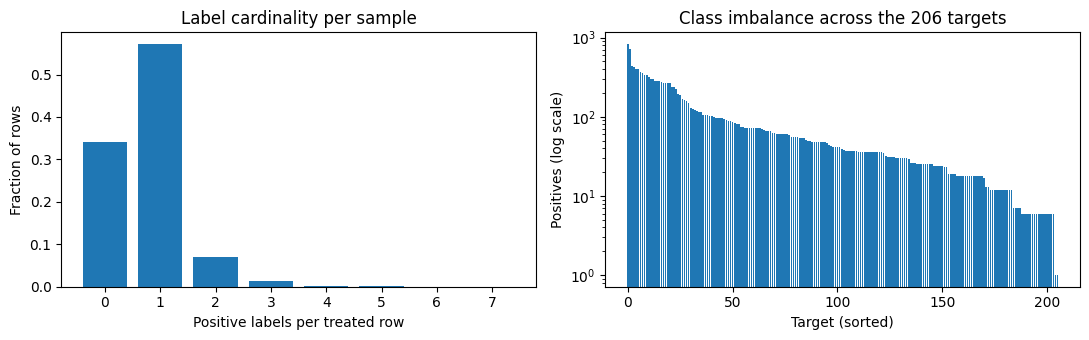

Distinct drugs (treated rows): 3288 | rows per drug: median 6, max 718 | drugs with >= 10 rows: 111
Largest drugs (rows): 87d714366=718, 9f80f3f77=246, 8b87a7a83=203, 5628cb3ee=202, d08af5d4b=196
Distinct drug ids among control rows: 1 | shared with treated rows: 0
Rows held by drugs with more than N rows (candidates for HYBRID_MIN_ROWS):
  >   6 rows:  311 drugs, 22.0% of the rows
  >  12 rows:   43 drugs, 11.9% of the rows
  >  18 rows:    9 drugs, 9.8% of the rows
  >  30 rows:    8 drugs, 9.7% of the rows
  >  60 rows:    8 drugs, 9.7% of the rows
  > 100 rows:    8 drugs, 9.7% of the rows
CV scheme: grouped
Validation rows per fold: [3987, 4136, 5512, 3933, 4380] (ideal 4390)
Validation rows whose drug also appears in the training fold: 0.0%, 0.0%, 0.0%, 0.0%, 0.0%
Targets without positives in the training fold: [4, 4, 4, 3, 4] | in the validation fold: [35, 36, 35, 36, 34]
Preprocessing fold 0...
Preprocessing fold 1...
Preprocessing fold 2...
Preprocessing fold 3...
Preprocessin

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  fold 0 | resnet         | mean val loss over 3 seeds: 0.01923
  fold 0 | ft_transformer | mean val loss over 3 seeds: 0.01949
  fold 1 | resnet         | mean val loss over 3 seeds: 0.01888
  fold 1 | ft_transformer | mean val loss over 3 seeds: 0.01939
  fold 2 | resnet         | mean val loss over 3 seeds: 0.02262
  fold 2 | ft_transformer | mean val loss over 3 seeds: 0.02349
  fold 3 | resnet         | mean val loss over 3 seeds: 0.01993
  fold 3 | ft_transformer | mean val loss over 3 seeds: 0.01995
  fold 4 | resnet         | mean val loss over 3 seeds: 0.01844
  fold 4 | ft_transformer | mean val loss over 3 seeds: 0.01923
resnet         log loss OOF: 0.01971
ft_transformer log loss OOF: 0.01992
[catboost | fold 0] 4 constant target(s) in the training fold (excluded from the fit, smoothed prior)
[catboost | fold 0] val_loss=0.01925
[catboost | fold 1] 4 constant target(s) in the training fold (excluded from the fit, smoothed prior)
[catboost | fold 1] val_loss=0.01931
[catboos

In [21]:
# Step 14.0 - start from a clean state: no cached pipelines from previous runs
clear_cached_pipelines(WORK_DIR)

# Step 14.1 - load, clean and explore data; attach drug ids; drop control rows from training
raw_features, raw_targets, raw_test, sample_submission = load_raw_data(DATA_DIR)
features, targets = clean_and_align(raw_features, raw_targets)
explore_data(features, targets, save_path=f"{WORK_DIR}/eda_summary.png")

# drug_id of every row (Step 2.4), taken BEFORE the control rows are dropped
drug_ids_all = align_drug_ids(features["sig_id"], load_drug_map(DATA_DIR))

trt_mask_train = features["cp_type"] != CTL_LABEL
describe_drugs(drug_ids_all[trt_mask_train.values], drug_ids_all[~trt_mask_train.values])
features = features[trt_mask_train].reset_index(drop=True)
targets = targets[trt_mask_train].reset_index(drop=True)
drug_ids = drug_ids_all[trt_mask_train.values]

# Step 14.2 - feature engineering
g_cols = [c for c in features.columns if c.startswith("g-")]
c_cols = [c for c in features.columns if c.startswith("c-")]

features = add_row_statistics(features, g_cols, c_cols)
features = encode_categoricals(features, dummy_cols=["cp_time", "cp_dose"])

feature_cols = [c for c in features.columns if c not in ("sig_id", "cp_type")]
target_cols = [c for c in targets.columns if c != "sig_id"]
dummy_cols = [c for c in feature_cols if c.startswith("cp_time_") or c.startswith("cp_dose_")]

X = features[feature_cols].values
Y = targets[target_cols].values

# Step 14.2b - CV splits: grouped by drug_id, hybrid or row-wise, depending on CV_SCHEME
print(f"CV scheme: {CV_SCHEME}")
split_groups = make_split_groups(drug_ids, CV_SCHEME, HYBRID_MIN_ROWS)   # None for "row"
splits = make_outer_splits(Y, split_groups, CV_SCHEME, N_FOLDS, RANDOM_STATE)
split_summary = describe_splits(splits, Y, drug_ids)   # always reported on the real drug ids

# Step 14.3 - neural-network CV: ResNet + FT-Transformer, multi-seed
time_start = time.time()
oof = run_cross_validation(X, Y, splits, split_groups, feature_cols, g_cols, c_cols, dummy_cols)
time_nn_cv_done = time.time()
for name in MODEL_NAMES:
    print(f"{name:14s} log loss OOF: {compute_moa_log_loss(Y, oof[name]):.5f}")

# Step 14.4 - CatBoost CV, RankGauss features WITHOUT PCA
oof_catboost = run_cross_validation_catboost(X, Y, feature_cols, dummy_cols, splits)
time_catboost_cv_done = time.time()
print(f"catboost       log loss OOF: {compute_moa_log_loss(Y, oof_catboost):.5f}")
print(f"[timing] NN CV: {(time_nn_cv_done - time_start) / 60:.1f} min | "
      f"CatBoost CV: {(time_catboost_cv_done - time_nn_cv_done) / 60:.1f} min")

ALL_MODEL_NAMES = MODEL_NAMES + ("catboost",)
oof["catboost"] = oof_catboost

# Step 14.5 - ensemble blending with nested CV on the weights
oof_list = [oof[name] for name in ALL_MODEL_NAMES]
final_weights, nested_mean, nested_std = nested_blend_validation(oof_list, Y, splits)
weights = dict(zip(ALL_MODEL_NAMES, final_weights))

# In-sample reference: weights fitted on ALL OOF rows (optimistic by construction)
in_sample_weights = optimize_blend_weights(oof_list, Y)
oof_blend_in_sample = sum(w * oof[name]
                          for w, name in zip(in_sample_weights, ALL_MODEL_NAMES))
blend_score_in_sample = compute_moa_log_loss(Y, oof_blend_in_sample)

print(f"Ensemble log loss, in-sample weights: {blend_score_in_sample:.5f}")
print(f"Ensemble log loss, nested (honest):   {nested_mean:.5f} +/- {nested_std:.5f}")
print(f"Optimism of in-sample score: {nested_mean - blend_score_in_sample:.2e}")

# Leaderboard-style estimate: control rows (predicted 0, true 0) add ~0 loss,
# so the all-rows mean is the treated-only mean scaled by the treated share.
test_treated_share = float((raw_test["cp_type"] != CTL_LABEL).mean())
leaderboard_style_estimate = nested_mean * test_treated_share
print(f"Treated share in test: {test_treated_share:.3f} | "
      f"leaderboard-style estimate: {leaderboard_style_estimate:.5f}")

# Step 14.6 - experiment logging
log_experiment(
    run_name=f"moa_ensemble_{CV_SCHEME}",
    params={"cv_scheme": CV_SCHEME, "hybrid_min_rows": HYBRID_MIN_ROWS, "n_unique_drugs": int(len(np.unique(drug_ids))),
            "split_summary": split_summary,
            "seeds": SEEDS, "n_folds": N_FOLDS, "epochs": EPOCHS,
            "hyperparameters": HYPERPARAMETERS_USED, "hyperparameters_source": HYPERPARAMETERS_SOURCE,
            "pca_g_components": PCA_G_COMPONENTS, "pca_c_components": PCA_C_COMPONENTS,
            "n_quantiles": N_QUANTILES, "variance_threshold": VARIANCE_THRESHOLD,
            "label_smoothing": LABEL_SMOOTHING,
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "inner_val_fraction": INNER_VAL_FRACTION,
            "model_names": list(ALL_MODEL_NAMES)},
    metrics={
        **{f"{name}_oof": compute_moa_log_loss(Y, oof[name]) for name in ALL_MODEL_NAMES},
        "blend_oof_in_sample": blend_score_in_sample,
        "blend_oof_nested": nested_mean,
        "blend_oof_nested_std": nested_std,
        "leaderboard_style_estimate": leaderboard_style_estimate,
        **{f"w_{name}": float(weights[name]) for name in ALL_MODEL_NAMES},
    },
)

# Step 14.7 - test set: preprocessing and inference for all models
trt_mask_test = raw_test["cp_type"] != CTL_LABEL
test_trt = raw_test[trt_mask_test].reset_index(drop=True)
test_trt = add_row_statistics(test_trt, g_cols, c_cols)
test_trt = encode_categoricals(test_trt, dummy_cols=["cp_time", "cp_dose"],
                               reference_columns=feature_cols)
X_test_raw = test_trt[feature_cols].values

# Two consistent feature variants, matching what each model was trained on
# (see Step 9): PCA features for resnet, raw RankGauss features (no PCA,
# the same pipeline used by CatBoost) for the FT-Transformer.
X_test_final_by_fold_pca = {
    fold: apply_fold_pipeline(X_test_raw, fold) for fold in range(N_FOLDS)
}
X_test_final_by_fold_raw = {
    fold: apply_fold_pipeline_raw(X_test_raw, fold) for fold in range(N_FOLDS)
}

time_inference_start = time.time()
preds_test = predict_test_set_nn(
    X_test_final_by_fold_pca, X_test_final_by_fold_raw, num_targets=Y.shape[1]
)
preds_test["catboost"] = predict_test_set_catboost(X_test_raw, num_targets=Y.shape[1])
final_test_preds = sum(weights[name] * preds_test[name] for name in ALL_MODEL_NAMES)
time_inference_done = time.time()
print(f"[timing] Test-set inference: {(time_inference_done - time_inference_start) / 60:.1f} min | "
      f"Total run: {(time_inference_done - time_start) / 60:.1f} min")

# Step 14.8 - build, check and export the submission
submission = build_submission(raw_test, sample_submission, target_cols,
                              final_test_preds, trt_mask_test)

# Final sanity check, run on the object actually written to disk
sanity_check_submission(submission, sample_submission, raw_test, target_cols)

submission_path = f"{WORK_DIR}/submission.csv"
submission.to_csv(submission_path, index=False)
print(f"{submission_path} written successfully.")

In [22]:
# Step 14.9 - export metadata needed by the inference notebook
metadata = {
    "feature_cols": feature_cols,
    "g_cols": g_cols,
    "c_cols": c_cols,
    "target_cols": target_cols,
    "dummy_cols": dummy_cols,
    "weights": {name: float(weights[name]) for name in ALL_MODEL_NAMES},
    "n_folds": N_FOLDS,
    "seeds": SEEDS,
    "versions": ENVIRONMENT_VERSIONS,
    "cv_scheme": CV_SCHEME,     # not read by the inference notebook; documents how the artifacts were validated
    # Constructor arguments of the networks: the inference notebook needs them to rebuild the same
    # architecture before loading the weights (a different hidden size or number of blocks would not load)
    "model_hyperparameters": MODEL_KWARGS,
    "hyperparameters": HYPERPARAMETERS_USED,     # everything that was used, for documentation
}

with open(f"{WORK_DIR}/requirements-frozen.txt", "w") as requirements_file:
    for name in PACKAGE_NAMES:
        requirements_file.write(f"{name}=={ENVIRONMENT_VERSIONS[name].split('+')[0]}\n")

with open(f"{WORK_DIR}/metadata.json", "w") as metadata_file:
    json.dump(metadata, metadata_file)

# Row-level bookkeeping, so that this run's OOF predictions can be matched to rows, drugs and
# folds later on (not needed for inference; not part of the artifacts Dataset)
fold_of_row = np.full(len(Y), -1, dtype=int)
for fold, (_, val_idx) in enumerate(splits):
    fold_of_row[val_idx] = fold
np.save(f"{WORK_DIR}/cv_fold_of_row.npy", fold_of_row)
np.save(f"{WORK_DIR}/train_sig_ids.npy", features["sig_id"].values.astype(str))
np.save(f"{WORK_DIR}/train_drug_ids.npy", drug_ids)

## 15. Final checks, per-target analysis and CV-protocol diagnostics
* **15.1–15.3:** fp16 vs fp32 check, trivial baseline, saved OOF predictions and model-contribution checks.
* **15.4 — per-target error analysis.** Which MoAs are hardest, and how the models behave on the targets with fewer than `RARE_THRESHOLD` positives. The raw per-target loss is **not** a measure of difficulty (a rare target has a small loss almost by construction), so two quantities are used: the *skill* relative to the per-target prior baseline (`1 − loss / baseline loss`, how much the model learns) and the *share of the total loss* (where the points to gain are). Confidence intervals come from a bootstrap over drugs, not over rows.
* **15.5 — CV-protocol diagnostics.** Seen vs unseen drugs, how much of the gap to the Kaggle score the current protocol reproduces, and (if `REFERENCE_OOF_DIR` is set) a per-target comparison with the row-wise run.

In [23]:
# Step 15.1 - check: effect of fp16 autocast on the out-of-fold log loss (fold 0, first seed)
check_fold, check_seed = 0, SEEDS[0]
val_idx = splits[check_fold][1]
y_val = Y[val_idx]
val_features = {
    "resnet": apply_fold_pipeline(X[val_idx], check_fold),
    "ft_transformer": apply_fold_pipeline_raw(X[val_idx], check_fold),
}
check_device = torch.device("cuda:0" if N_GPUS > 0 else "cpu")
for model_name, X_val_check in val_features.items():
    model = _build_model(model_name, X_val_check.shape[1], y_val.shape[1])
    checkpoint_path = f"{WORK_DIR}/best_{model.name}_fold_{check_fold}_seed{check_seed}.pth"
    model.load_state_dict(torch.load(checkpoint_path, map_location=check_device, weights_only=True))
    model = model.to(check_device)
    batch_size = INFERENCE_BATCH_SIZE_BY_MODEL[model_name]
    preds_fp32 = predict_probabilities(model, X_val_check, check_device, batch_size, use_amp=False)
    preds_amp = predict_probabilities(model, X_val_check, check_device, batch_size, use_amp=USE_AMP)
    print(f"{model_name:14s} | loss fp32 {compute_moa_log_loss(y_val, preds_fp32):.6f} | "
          f"loss fp16 {compute_moa_log_loss(y_val, preds_amp):.6f} | "
          f"max abs diff {np.abs(preds_fp32 - preds_amp).max():.2e}")
    del model

resnet         | loss fp32 0.019282 | loss fp16 0.019282 | max abs diff 6.11e-04
ft_transformer | loss fp32 0.019451 | loss fp16 0.019450 | max abs diff 1.63e-03


In [24]:
# Step 15.2 - trivial baseline: per-target positive rate of the training fold (smoothed, 0.5 pseudo-counts)
baseline_oof = np.zeros_like(Y, dtype=np.float64)
for train_idx, val_idx in splits:
    baseline_oof[val_idx] = (Y[train_idx].sum(axis=0) + 0.5) / (len(train_idx) + 1.0)
baseline_score = compute_moa_log_loss(Y, baseline_oof)
print(f"Baseline OOF log loss: {baseline_score:.5f} | "
      f"ensemble (nested) is {100 * (1 - nested_mean / baseline_score):.1f}% lower")

Baseline OOF log loss: 0.02370 | ensemble (nested) is 18.7% lower


In [25]:
# Step 15.3 - save the OOF predictions; how different are the models' errors?
for name in ALL_MODEL_NAMES:
    np.save(f"{WORK_DIR}/oof_{name}.npy", oof[name])
np.save(f"{WORK_DIR}/oof_targets.npy", Y)

residuals = pd.DataFrame({name: (oof[name] - Y).ravel() for name in ALL_MODEL_NAMES})
positive_cells = Y.ravel() == 1
print("Residual correlation, all cells:");       print(residuals.corr().round(3))
print("Residual correlation, positive cells:");  print(residuals[positive_cells].corr().round(3))

# Direct test of each model's contribution: nested blend without that model
for dropped in ALL_MODEL_NAMES:
    kept = [name for name in ALL_MODEL_NAMES if name != dropped]
    _, score_without, std_without = nested_blend_validation([oof[name] for name in kept], Y, splits)
    print(f"Blend without {dropped}: {score_without:.5f} +/- {std_without:.5f}")

Residual correlation, all cells:
                resnet  ft_transformer  catboost
resnet           1.000           0.985     0.977
ft_transformer   0.985           1.000     0.984
catboost         0.977           0.984     1.000
Residual correlation, positive cells:
                resnet  ft_transformer  catboost
resnet           1.000           0.891     0.806
ft_transformer   0.891           1.000     0.832
catboost         0.806           0.832     1.000
[nested blend] fold 0: score=0.01888 weights=[0.439 0.561]
[nested blend] fold 1: score=0.01876 weights=[0.415 0.585]
[nested blend] fold 2: score=0.02138 weights=[0.585 0.415]
[nested blend] fold 3: score=0.01937 weights=[0.439 0.561]
[nested blend] fold 4: score=0.01842 weights=[0.438 0.562]
Honest nested-blend score: 0.01948 +/- 0.00105 (mean weighted by fold rows)
Final weights (nested mean): [0.4632 0.5368]
Blend without resnet: 0.01948 +/- 0.00105
[nested blend] fold 0: score=0.01882 weights=[0.569 0.431]
[nested blend] fold 

In [26]:
# Step 15.4 - per-target error analysis on the OOF predictions
from sklearn.metrics import roc_auc_score, average_precision_score

PREVALENCE_BINS = [0, 4, 9, 19, 49, 99, np.inf]
PREVALENCE_LABELS = ["1-4", "5-9", "10-19", "20-49", "50-99", "100+"]
REPORT_COLUMNS = ["target", "n_pos", "n_drugs", "loss", "skill", "loss_share",
                  "calibration", "auc", "ap"]


def loss_matrix(Y, P, eps=CLIP_EPS):
    """Element-wise binary log loss, shape (rows, targets)."""
    P = np.clip(np.asarray(P, dtype=np.float64), eps, 1 - eps)
    return -(Y * np.log(P) + (1 - Y) * np.log(1 - P))


def per_target_report(Y, P, baseline_P, target_cols, drug_ids):
    """One row per target.
    skill        1 - loss / baseline loss (baseline = smoothed per-target prior of the training
                 fold): how much the model learns beyond the prior. 0 = nothing, <0 = worse.
    loss_share   fraction of the total loss carried by the target: where the points to gain are.
    calibration  expected positives (sum of predicted probabilities) / observed positives.
    n_drugs      distinct drugs among the positives: few drugs for many positives means the
                 target is close to a drug-identity label.
    AUC / AP are reported but unreliable below ~5 positives.
    Returns the report and the two (rows x targets) loss matrices, for the bootstrap."""
    loss_m, base_m = loss_matrix(Y, P), loss_matrix(Y, baseline_P)
    loss, base = loss_m.mean(axis=0), base_m.mean(axis=0)
    n_targets = Y.shape[1]
    report = pd.DataFrame({
        "target": target_cols,
        "n_pos": Y.sum(axis=0).astype(int),
        "n_drugs": [len(np.unique(drug_ids[Y[:, t] == 1])) for t in range(n_targets)],
        "loss": loss,
        "baseline_loss": base,
        "skill": 1 - loss / base,
        "loss_share": loss / loss.sum(),
        "expected_pos": np.clip(P, CLIP_EPS, 1 - CLIP_EPS).sum(axis=0),
        "auc": [roc_auc_score(Y[:, t], P[:, t]) for t in range(n_targets)],
        "ap": [average_precision_score(Y[:, t], P[:, t]) for t in range(n_targets)],
    })
    report["calibration"] = report["expected_pos"] / report["n_pos"]
    report["prevalence_bin"] = pd.cut(report["n_pos"], PREVALENCE_BINS, labels=PREVALENCE_LABELS)
    return report, loss_m, base_m


def aggregate_by_bin(report):
    """Skill and loss share per prevalence bin. The skill is aggregated as
    1 - sum(loss) / sum(baseline loss), not as a mean of per-target skills."""
    grouped = report.groupby("prevalence_bin", observed=True)
    return pd.DataFrame({
        "n_targets": grouped.size(),
        "n_pos_total": grouped["n_pos"].sum(),
        "loss_share": grouped["loss_share"].sum(),
        "skill": 1 - grouped["loss"].sum() / grouped["baseline_loss"].sum(),
        "calibration": grouped["expected_pos"].sum() / grouped["n_pos"].sum(),
        "median_auc": grouped["auc"].median(),
    })


def bootstrap_skill_ci(loss_m, base_m, drug_ids, target_mask, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    """95% bootstrap interval of the aggregate skill of the selected targets.
    Drugs, not rows, are resampled: rows of the same drug are correlated, and resampling
    rows would give intervals that are too narrow."""
    if not target_mask.any():
        return float("nan"), float("nan")
    unique_drugs, drug_of_row = np.unique(drug_ids, return_inverse=True)
    n_drugs = len(unique_drugs)
    loss_per_drug = np.bincount(drug_of_row, weights=loss_m[:, target_mask].sum(axis=1), minlength=n_drugs)
    base_per_drug = np.bincount(drug_of_row, weights=base_m[:, target_mask].sum(axis=1), minlength=n_drugs)
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(n_drugs, np.full(n_drugs, 1.0 / n_drugs), size=n_boot)   # (n_boot, n_drugs)
    skills = 1 - (draws @ loss_per_drug) / (draws @ base_per_drug)
    low, high = np.percentile(skills, [2.5, 97.5])
    return float(low), float(high)


# The blend uses the nested-mean weights of Step 14.5 (they were fitted on these same OOF
# predictions, but with three weights the optimism is negligible, see Step 14.5)
oof_blend = sum(weights[name] * oof[name] for name in ALL_MODEL_NAMES)
analysis_models = {**{name: oof[name] for name in ALL_MODEL_NAMES}, "blend": oof_blend}

target_reports = {}
for model_name, model_preds in analysis_models.items():
    report, loss_m, base_m = per_target_report(Y, model_preds, baseline_oof, target_cols, drug_ids)
    target_reports[model_name] = report
    report.drop(columns="prevalence_bin").to_csv(f"{WORK_DIR}/per_target_report_{model_name}.csv", index=False)

    is_rare = (report["n_pos"] < RARE_THRESHOLD).values
    print(f"{model_name:14s}", end="")
    for label, mask in ((f"rare (<{RARE_THRESHOLD} pos, n={int(is_rare.sum())})", is_rare),
                        (f"other (n={int((~is_rare).sum())})", ~is_rare)):
        skill = 1 - report.loc[mask, "loss"].sum() / report.loc[mask, "baseline_loss"].sum()
        low, high = bootstrap_skill_ci(loss_m, base_m, drug_ids, mask)
        share = report.loc[mask, "loss_share"].sum()
        calibration = report.loc[mask, "expected_pos"].sum() / report.loc[mask, "n_pos"].sum()
        print(f" | {label}: skill {skill:+.3f} [{low:+.3f}, {high:+.3f}], "
              f"loss share {share:.1%}, expected/observed pos {calibration:.2f}", end="")
    print()
del loss_m, base_m

blend_report = target_reports["blend"]
print("\nBlend, by number of positives (skill vs per-target prior; loss share of the total):")
print(aggregate_by_bin(blend_report).round(4).to_string())

print("\nSkill by prevalence bin and model:")
print(pd.DataFrame({name: aggregate_by_bin(report)["skill"]
                    for name, report in target_reports.items()}).round(4).to_string())

print("\nBlend: the 10 targets with the largest share of the total loss:")
print(blend_report.nlargest(10, "loss_share")[REPORT_COLUMNS].round(4).to_string(index=False))

print("\nBlend: the 10 targets with the lowest skill (among those with >= 5 positives):")
print(blend_report[blend_report["n_pos"] >= 5].nsmallest(10, "skill")[REPORT_COLUMNS].round(4).to_string(index=False))

rare_report = blend_report[blend_report["n_pos"] < RARE_THRESHOLD]
print(f"\nBlend, rare targets: {int((rare_report['skill'] <= 0).sum())} of {len(rare_report)} "
      f"have skill <= 0 (the model does not beat the prior); "
      f"median AUC {rare_report['auc'].median():.3f} (unreliable below ~5 positives)")

identity_like = blend_report[(blend_report["n_pos"] >= 10) & (blend_report["n_drugs"] <= 3)]
print(f"Targets with >= 10 positives coming from <= 3 drugs (close to drug-identity labels): "
      f"{len(identity_like)}")
if len(identity_like):
    print(identity_like[REPORT_COLUMNS].round(4).to_string(index=False))
print(f"\nFull per-target tables saved to {WORK_DIR}/per_target_report_<model>.csv")

resnet         | rare (<20 pos, n=53): skill +0.032 [-0.045, +0.084], loss share 6.0%, expected/observed pos 1.97 | other (n=153): skill +0.176 [+0.100, +0.265], loss share 94.0%, expected/observed pos 0.95
ft_transformer | rare (<20 pos, n=53): skill +0.033 [-0.018, +0.071], loss share 6.0%, expected/observed pos 1.83 | other (n=153): skill +0.166 [+0.114, +0.225], loss share 94.0%, expected/observed pos 0.96
catboost       | rare (<20 pos, n=53): skill -0.004 [-0.042, +0.026], loss share 6.2%, expected/observed pos 1.18 | other (n=153): skill +0.174 [+0.113, +0.246], loss share 93.8%, expected/observed pos 0.89
blend          | rare (<20 pos, n=53): skill +0.044 [-0.013, +0.085], loss share 6.1%, expected/observed pos 1.66 | other (n=153): skill +0.197 [+0.130, +0.273], loss share 93.9%, expected/observed pos 0.93

Blend, by number of positives (skill vs per-target prior; loss share of the total):
                n_targets  n_pos_total  loss_share   skill  calibration  median_auc
pre

In [27]:
# Step 15.5 - CV-protocol diagnostics
from scipy.stats import spearmanr


def seen_vs_unseen_loss(Y, P, splits, drug_ids):
    """Mean row loss of the validation rows whose drug is, or is not, in the training fold.
    Descriptive only: frequently measured drugs differ systematically from rare ones, so the
    difference between the two groups is not a causal estimate of the leakage."""
    row_loss = loss_matrix(Y, P).mean(axis=1)
    seen = np.zeros(len(Y), dtype=bool)
    for train_idx, val_idx in splits:
        seen[val_idx] = np.isin(drug_ids[val_idx], drug_ids[train_idx])
    return {"share_seen": float(seen.mean()),
            "loss_seen": float(row_loss[seen].mean()) if seen.any() else float("nan"),
            "loss_unseen": float(row_loss[~seen].mean()) if (~seen).any() else float("nan")}


# (a) this run: how many validation rows have their drug in the training fold
print(f"CV scheme of this run: {CV_SCHEME}")
for model_name in (*ALL_MODEL_NAMES, "blend"):
    stats = seen_vs_unseen_loss(Y, analysis_models[model_name], splits, drug_ids)
    print(f"  {model_name:14s} | validation rows with seen drug: {stats['share_seen']:.1%} | "
          f"loss seen {stats['loss_seen']:.5f} | loss unseen {stats['loss_unseen']:.5f}")

# (b) gap between the CV estimate and the Kaggle score, on the same scale (treated rows only).
# The public treated share is used for the private score too: the share in the hidden part of
# the test set is unknown, so the rescaling is approximate.
private_treated_scale = KAGGLE_PRIVATE_SCORE / test_treated_share
public_treated_scale = KAGGLE_PUBLIC_SCORE / test_treated_share
gap_to_private = private_treated_scale - ROW_CV_REFERENCE
print(f"\nTreated-rows scale: row-wise CV (reference run) {ROW_CV_REFERENCE:.5f} | "
      f"this run, nested blend {nested_mean:.5f} | "
      f"Kaggle private / {test_treated_share:.3f} = {private_treated_scale:.5f} | "
      f"Kaggle public / {test_treated_share:.3f} = {public_treated_scale:.5f}")
if CV_SCHEME != "row" and gap_to_private > 0:
    reproduced = (nested_mean - ROW_CV_REFERENCE) / gap_to_private
    if reproduced > 1.15:
        verdict = "overshoot: this CV is MORE pessimistic than the Kaggle private score"
    elif reproduced >= 0.85:
        verdict = "close to the Kaggle private score"
    else:
        verdict = "only part of the gap: other causes remain open"
    print(f"Share of the (row-wise CV -> Kaggle private) gap reproduced by the {CV_SCHEME} CV: {reproduced:.0%} -> {verdict}. "
          f"Relative to the private score on the treated-rows scale: {nested_mean / private_treated_scale - 1:+.1%}; "
          f"relative to the public score: {nested_mean / public_treated_scale - 1:+.1%}. "
          "Indirect evidence only: composition shift of the test set, the approximate rescaling and "
          "test compounds seen in training are not excluded.")
elif CV_SCHEME == "row":
    print("This run uses the row-wise protocol: the gap to the Kaggle score is not reproduced by construction.")

# (c) comparison with the row-wise run, per target (needs its saved OOF predictions)
if CV_SCHEME != "row" and REFERENCE_OOF_DIR is not None:
    reference_targets = np.load(f"{REFERENCE_OOF_DIR}/oof_targets.npy")
    assert reference_targets.shape == Y.shape and (reference_targets == Y).all(), \
        "oof_targets.npy of the reference run does not match the targets of this run"
    reference_oof = {name: np.load(f"{REFERENCE_OOF_DIR}/oof_{name}.npy") for name in ALL_MODEL_NAMES}
    reference_blend = sum(REFERENCE_BLEND_WEIGHTS[name] * reference_oof[name] for name in ALL_MODEL_NAMES)

    # The row-wise folds are rebuilt: the splitter only looks at the labels, which are checked above
    reference_splits = make_outer_splits(Y, drug_ids, "row", N_FOLDS, RANDOM_STATE)
    reference_baseline = np.zeros_like(Y, dtype=np.float64)
    for train_idx, val_idx in reference_splits:
        reference_baseline[val_idx] = (Y[train_idx].sum(axis=0) + 0.5) / (len(train_idx) + 1.0)

    reference_loss = compute_moa_log_loss(Y, reference_blend)
    print(f"\nReference (row-wise) blend OOF log loss: {reference_loss:.5f}")
    if abs(reference_loss - ROW_CV_REFERENCE) > 2e-4:
        print(f"WARNING: it differs from ROW_CV_REFERENCE ({ROW_CV_REFERENCE:.5f}) by more than 2e-4: "
              "the reference OOF may not match this run's rows or weights.")

    print("Seen vs unseen drugs in the row-wise OOF (descriptive, not causal):")
    for model_name in (*ALL_MODEL_NAMES, "blend"):
        reference_preds = reference_blend if model_name == "blend" else reference_oof[model_name]
        stats = seen_vs_unseen_loss(Y, reference_preds, reference_splits, drug_ids)
        print(f"  {model_name:14s} | validation rows with seen drug: {stats['share_seen']:.1%} | "
              f"loss seen {stats['loss_seen']:.5f} | loss unseen {stats['loss_unseen']:.5f}")

    reference_report, _, _ = per_target_report(Y, reference_blend, reference_baseline, target_cols, drug_ids)
    current_report = target_reports["blend"]

    print(f"\nBlend skill by prevalence bin, row-wise vs {CV_SCHEME} CV:")
    print(pd.DataFrame({"row": aggregate_by_bin(reference_report)["skill"],
                        CV_SCHEME: aggregate_by_bin(current_report)["skill"]}).round(4).to_string())

    comparison = pd.DataFrame({
        "target": current_report["target"], "n_pos": current_report["n_pos"],
        "n_drugs": current_report["n_drugs"],
        "skill_row": reference_report["skill"], "skill_cv": current_report["skill"]})
    comparison["delta"] = comparison["skill_cv"] - comparison["skill_row"]
    comparison["pos_per_drug"] = comparison["n_pos"] / comparison["n_drugs"]
    comparison.to_csv(f"{WORK_DIR}/per_target_row_vs_cv.csv", index=False)

    eligible = comparison[comparison["n_pos"] >= 10]
    rho, p_value = spearmanr(eligible["pos_per_drug"], eligible["delta"])
    print(f"\nSpearman correlation between positives-per-drug and the change in skill "
          f"(targets with >= 10 positives, n={len(eligible)}): {rho:+.3f} (p={p_value:.3g}). "
          "Negative = targets dominated by few drugs lose more under the drug-aware CV.")
    print("The 10 targets whose skill drops the most (>= 10 positives):")
    print(eligible.nsmallest(10, "delta").round(4).to_string(index=False))
elif CV_SCHEME != "row":
    print("\nSet REFERENCE_OOF_DIR (Step 1.3) to the oof_*.npy of the row-wise run to also get the "
          "per-target comparison between the two protocols.")

CV scheme of this run: grouped
  resnet         | validation rows with seen drug: 0.0% | loss seen nan | loss unseen 0.01971
  ft_transformer | validation rows with seen drug: 0.0% | loss seen nan | loss unseen 0.01992
  catboost       | validation rows with seen drug: 0.0% | loss seen nan | loss unseen 0.01979
  blend          | validation rows with seen drug: 0.0% | loss seen nan | loss unseen 0.01921

Treated-rows scale: row-wise CV (reference run) 0.01607 | this run, nested blend 0.01926 | Kaggle private / 0.910 = 0.01795 | Kaggle public / 0.910 = 0.02049
Share of the (row-wise CV -> Kaggle private) gap reproduced by the grouped CV: 169% -> overshoot: this CV is MORE pessimistic than the Kaggle private score. Relative to the private score on the treated-rows scale: +7.3%; relative to the public score: -6.0%. Indirect evidence only: composition shift of the test set, the approximate rescaling and test compounds seen in training are not excluded.

Reference (row-wise) blend OOF log l